# Анализ лояльности пользователей Яндекс Афиши

  - Автор: Васильев С.А.
  - Дата: 07.11.2026

### Цели и задачи проекта

#### Цель: 

Команда маркетинга хочет лучше понимать поведение пользователей. Для этого они просят провести исследовательский анализ данных, чтобы понять, какие пользователи с большей вероятностью возвращаются на платформу и делают заказы повторно. Это позволит:
Быстро выявлять перспективных клиентов и предлагать им персонализированные условия.
 - Точно настраивать рекламу на аудитории с высокой вероятностью возврата.
 - Оптимизировать маркетинговые бюджеты.
 - Повысить общий уровень удержания клиентов.

#### Задачи:

 1. Выгрузка данных из базы sql 
 
 2. Знакомство с данными
 
 3. Предобработка данных
 
 4. Создание профиля пользователя
 
 5. Исследовательский анализ данных:
    - Детальное изучение данных
    - Исследование признаков первого заказа и их связи с возвращением на платформу
    - Исследование поведения пользователей через показатели выручки и состава заказа
    - Исследование временных характеристик первого заказа и их влияния на повторные покупки
    - Корреляционный анализ количества покупок и признаков пользователя
 

6. Общие выводы и рекомендации


### Описание данных

Датасет содержит соедующую информацию:

  - `user_id` — уникальный идентификатор пользователя, совершившего заказ;
  - `device_type_canonical` — тип устройства, с которого был оформлен заказ ( mobile — мобильные устройства, desktop — стационарные);
  - `order_id` — уникальный идентификатор заказа;
  - `order_dt` — дата создания заказа (используйте данные created_dt_msk );
  - `order_ts` — дата и время создания заказа (используйте данные created_ts_msk );
  - `currency_code` — валюта оплаты;
  - `revenue` — выручка от заказа;
  - `tickets_count` — количество купленных билетов;
  - `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
  - `event_id` — уникальный идентификатор мероприятия;
  - `service_name` — название билетного оператора;
  - `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
  - `region_name` — название региона, в котором прошло мероприятие;
  - `city_name` — название города, в котором прошло мероприятие.

### Содержимое проекта

#### Оглавление


[1. Загрузка данных и их предобработка](#1.-Загрузка-данных-и-их-предобработка)

   - [Задача 1.1: Выгрузка данных из sql](#Задача-1.1:-Выгрузка-данных-из-sql)
   
   
   - [Задача 1.2: Общая информация о выгруженном датасете ](#Задача-1.2:-Общая-информация-о-выгруженном-датасете )

[2. Предобработка данных](#2.-Предобработка-данных)

   - [Задача 2.1: Приведение валют к единому формату](#Задача-2.1:-Приведение-валют-к-единому-формату)
   
   
   - [Задача 2.2: Предобработка данных](#Задача-2.2:-Предобработка-данных)
   
   
   - [Промежуточные результаты этапа предобработки](#Промежуточные-результаты-этапа-предобработки:)
   

[3. Создание профиля пользователя](#3.-Создание-профиля-пользователя)
    
   - [Задача 3.1: Построение профиля пользователя](#Задача-3.1:-Построение-профиля-пользователя)
   
   
   - [Задача 3.2: Поиск аномалий в профиле пользователя](#Задача-3.2:-Поиск-аномалий-в-профиле-пользователя)
   
   
[4. Исследовательский анализ данных](#4.-Исследовательский-анализ-данных)
   
   - [4.1. Исследование признаков первого заказа и их связи с возвращением на платформу](#4.1-Исследование-признаков-первого-заказа-и-их-связи-с-возвращением-на-платформу)
   
    - [Задача 4.1.1 Изучение распределения пользователей по признакам](#Задача-4.1.1-Изучение-распределения-пользователей-по-признакам)
    - [Задача 4.1.2 Анализ возврата пользователей ](#Задача-4.1.2-Анализ-возврата-пользователей)
    - [Задача 4.1.3. Проверка продуктовых гипотез](#Задача-4.1.3.-Проверка-продуктовых-гипотез)
   
   
   - [4.2. Исследование поведения пользователей через показатели выручки и состава заказа](#4.2.-Исследование-поведения-пользователей-через-показатели-выручки-и-состава-заказа)
   
   
   - [4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки](#4.3.-Исследование-временных-характеристик-первого-заказа-и-их-влияния-на-повторные-покупки)
   

   - [4.4. Корреляционный анализ количества покупок и признаков пользователя](#4.4.-Корреляционный-анализ-количества-покупок-и-признаков-пользователя)
   
[5. Общий вывод и рекомендации](#5.-Общий-вывод-и-рекомендации)

---

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

#### Задача 1.1: Выгрузка данных из sql

Написать SQL-запрос, выгружающий в датафрейм pandas необходимые данные. 



---

In [1]:
# Импортируем библиотеки
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

# Загружаем библиотеку для выгрузки sql БД
from sqlalchemy import create_engine 

# Для чтения данных из env файла
import os
from dotenv import load_dotenv, find_dotenv
from pathlib import Path

In [2]:
current_file_dir = find_dotenv()

# Проверка наличия файла env
    
if not current_file_dir:
    raise FileNotFoundError(
        'файл env в папке проекта отсутствует'
        )

# Загрузка данных из env
    
load_dotenv(dotenv_path=current_file_dir, override=True)

db_user = os.getenv('DB_USER')
db_pwd = os.getenv('DB_PWD')
db_host = os.getenv('DB_HOST')
db_port = os.getenv('DB_PORT')
db_name = os.getenv('DB_NAME')

# Проверка на наличие данных в env
    
if not all([db_user, db_pwd, db_host, db_port, db_name]):
    raise ValueError(
        f'Ошибка: в файле env отсутствуют обязательные данные'
        )

# Устанавливаем соединение с БД
    
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_user,
    db_pwd,
    db_host,
    db_port,
    db_name,
    )

engine = create_engine(connection_string)

In [3]:
# SQL запрос для выгрузки данных
query = '''
SELECT
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    p.created_dt_msk::date - LAG(p.created_dt_msk::date) OVER (
        PARTITION BY p.user_id 
        ORDER BY p.created_dt_msk
    ) AS days_since_prev,
    e.event_id,
    e.event_name_code AS event_name,
    e.event_type_main,
    p.service_name,
    r.region_name,
    c.city_name
FROM afisha.purchases as p
LEFT JOIN afisha.events as e 
    ON p.event_id = e.event_id 
LEFT JOIN afisha.city as c 
    ON e.city_id = c.city_id
LEFT JOIN afisha.regions as r 
    ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop') AND e.event_type_main != 'фильм'
ORDER BY p.user_id
''' 

In [4]:
# Записываем в переменную
df = pd.read_sql_query(query, con=engine) 

[Назад к оглавлению](#Оглавление)

---

#### Задача 1.2: Общая информация о выгруженном датасете 

Изучить общую информацию о выгруженных данных. Оценить корректность выгрузки и объём полученных данных.


---

In [5]:
# Посмотрим на содержимое датасета
print('Первые 10 строк:')
display(df.head(10))
print('\nСлучайные 10 строк:')
display(df.sample(10, random_state=42)) # Исправлено
print('\nПоследние 10 строк:')
display(df.tail(10))

Первые 10 строк:


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк
5,000898990054619,mobile,2613713,2024-10-23,2024-10-23 15:12:00,rub,902.74,3,19.0,500862,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,Облачко,Лугоградская область,Кристалевск
6,00096d1f542ab2b,desktop,6636941,2024-08-15,2024-08-15 16:48:48,rub,917.83,4,NaN,201953,2f98d69f-4e60-4ffc-8f16-e539383526b1,театр,Край билетов,Каменевский регион,Глиногорск
7,000a55a418c128c,mobile,4657981,2024-09-29,2024-09-29 19:39:12,rub,47.78,1,NaN,265857,0d876e01-851e-458b-ba61-753e0e0c4063,театр,Лучшие билеты,Поленовский край,Дальнозолотск
8,000a55a418c128c,mobile,4657952,2024-10-15,2024-10-15 10:29:04,rub,74.84,2,16.0,271579,ddc795f8-7ef8-4eb0-b299-cb3e6ee24ba1,театр,Лучшие билеты,Поленовский край,Дальнозолотск
9,000cf0659a9f40f,mobile,6818017,2024-06-20,2024-06-20 10:35:26,rub,1421.91,4,NaN,516728,11be386f-7cb7-4aa1-a8e4-ba73a29c1af2,концерты,Лови билет!,Широковская область,Радужнополье



Случайные 10 строк:


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
195464,a3465bb7f920908,mobile,6943587,2024-10-25,2024-10-25 18:01:03,rub,689.23,5,0.0,174876,c0e9358b-581c-461b-bb70-adf877affb18,другое,Мой билет,Широковская область,Луговаярово
287418,fe237d2cfd6e503,mobile,7754224,2024-07-22,2024-07-22 13:12:20,rub,331.59,3,1.0,347900,9aca194a-6b84-48ef-8748-6f48a86cebd5,выставки,Прачечная,Каменевский регион,Глиногорск
42929,1a1514f0360ff18,mobile,4063597,2024-09-29,2024-09-29 10:56:08,rub,68.63,4,0.0,566686,3cae43c4-d28c-4a5b-a623-0037ebf2729a,другое,Лови билет!,Речиновская область,Дальнесветск
142669,75c7893ea1eb7ef,mobile,6827326,2024-09-21,2024-09-21 14:26:25,rub,243.78,2,0.0,14893,22af6c33-aaa7-43cf-90c8-03e6faec9afa,театр,Лучшие билеты,Яблоневская область,Светополье
179797,9256ac0cd3dd438,desktop,2485475,2024-10-31,2024-10-31 22:15:05,rub,83.66,2,0.0,589624,c9eb1fa4-257b-4290-975a-7fe34b46d11b,концерты,Мой билет,Каменевский регион,Глиногорск
215450,b4d585258d838b1,desktop,1709638,2024-06-21,2024-06-21 13:27:56,rub,77.80,1,NaN,508173,784f3c9b-f226-4cd6-bea1-367f0f320734,театр,Билеты без проблем,Горицветская область,Островецк
46282,1c2a2133e1df1b4,mobile,4279763,2024-09-05,2024-09-05 14:00:03,rub,1470.44,4,0.0,403590,99ae2f79-da1a-41e0-8c26-7046278d188d,стендап,Лови билет!,Каменевский регион,Глиногорск
264221,e6a9a8e9ed26841,mobile,5303608,2024-10-05,2024-10-05 10:13:18,rub,203.30,3,2.0,573041,c1f637f3-f9e5-4026-a465-f500102213ea,другое,Мой билет,Каменевский регион,Глиногорск
188368,9bbe3534bbaa8e1,mobile,810986,2024-10-24,2024-10-24 16:47:57,rub,340.49,2,0.0,552858,d6d659e6-1f36-43a0-9930-8c9f00588eaa,концерты,Мир касс,Каменевский регион,Глиногорск
33825,1290366e32d4f0f,desktop,6251270,2024-10-29,2024-10-29 10:46:52,kzt,388.82,4,0.0,579640,135646e0-3873-44b0-b1af-4502fdb72fdd,другое,Билеты без проблем,Верхоречная область,Серебрянка



Последние 10 строк:


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
290601,fffcd3dde79eb2c,mobile,4490593,2024-10-15,2024-10-15 23:20:36,rub,439.98,2,8.0,554081,eac4d50c-48ef-4b1d-a2dc-6f1420487b53,концерты,Мой билет,Каменевский регион,Глиногорск
290602,fffcd3dde79eb2c,mobile,851905,2024-10-16,2024-10-16 21:48:33,rub,1000.09,3,1.0,132543,63e142d3-9425-4d42-8b5d-936ef0b5353a,театр,Край билетов,Каменевский регион,Глиногорск
290603,fffcd3dde79eb2c,mobile,2070688,2024-10-22,2024-10-22 13:46:24,rub,478.41,3,6.0,572446,3f8555f5-b0b9-4780-94c9-afed2ab7f864,концерты,Быстробилет,Каменевский регион,Глиногорск
290604,fffcd3dde79eb2c,mobile,4326395,2024-10-26,2024-10-26 17:43:23,rub,414.12,4,4.0,571114,67173a55-dd4c-4f71-ba3a-adacd47464f4,другое,Билеты без проблем,Каменевский регион,Глиногорск
290605,fffcd3dde79eb2c,mobile,368620,2024-10-27,2024-10-27 18:00:57,rub,965.57,4,1.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск
290606,fffcd3dde79eb2c,mobile,368591,2024-10-27,2024-10-27 17:54:52,rub,965.57,4,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск
290607,fffcd3dde79eb2c,mobile,368562,2024-10-27,2024-10-27 17:53:53,rub,1448.36,6,0.0,33189,e3dcdb45-9eaa-4ce4-9b85-1562e548172e,другое,Весь в билетах,Каменевский регион,Глиногорск
290608,fffcd3dde79eb2c,desktop,8473772,2024-10-30,2024-10-30 13:37:43,rub,178.95,2,3.0,205231,74883818-57a6-494a-b162-bb0260877cbf,театр,Прачечная,Каменевский регион,Глиногорск
290609,fffeeb3c120cf0b,desktop,5526067,2024-09-24,2024-09-24 10:07:42,rub,661.53,2,NaN,454526,6f4c6a50-0106-407b-8f54-332c740b01da,стендап,Билеты без проблем,Широковская область,Ягодиновка
290610,ffff00725179321,mobile,813654,2024-09-25,2024-09-25 15:12:40,rub,802.25,2,NaN,284965,58574140-962c-49a3-af70-b773a05661a3,концерты,Мой билет,Малиновоярский округ,Верховино


In [6]:
# Выведем основную информацию о датасете
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

После первичного анализа датасета, можно выделить следующие моменты:
  - загрузка данных прошла корректно, только 1 столбец с пропусками, где они и должны быть `days_since_prev` - количество дней между заказами. NaN для пользователей сделавших только 1 заказ. далее подтвердим полученную информацию
  - количество строк 290611
  - стобцы по типу данных распределяются: datetime64[ns] - 2, float64 - 2, int64 - 3, object - 8, соответствуют значениям столбцов
  - Наименование таблиц корректное в виде snake_case, содержимое соответствует названиям столбцов
  - в 3х столбцах (`service_name`, `region_name`, `city_name`) данные имеют разный регистр, стоит привести к нижнему регистру и проверить на неявные дубликаты
  - Хоть датасет не занимает много памяти 33,3+ MB, можно оптимизировать размерность для числовых столбцов (`order_id`, `tickets_count`, `event_id`)
  - Столбец `revenue` - должен быть в типе float64, так как это выручка, чтобы не терять данные при оптимизации. Из-за пропусков в столбце `days_since_prev` привести его к типу int (что было бы логично - количество дней записаны как целочисленные значения) не получится без заполнения пропусков. Даже заполнение `0` можно ошибочно принять, что 2 заказа были сделаны менее чем за 1 день, заполнение не целесообразно для анализа. Но мы можем поменять разрядность
  - в данных имеются 2 вида валют rub и kzt - стоит привести к единому формату в рублях

[Назад к оглавлению](#Оглавление)

---

###  2. Предобработка данных


---

#### Задача 2.1: Приведение валют к единому формату

Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Привести выручку к единой валюте — российскому рублю.

Для этого использовать датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно скачать по [ссылке](https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv).

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраняем в новый столбец `revenue_rub`.

---

In [7]:
# загрузим данные о курсе тенге
tenge_rate_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

In [8]:
tenge_rate_df

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt
...,...,...,...,...
352,2024-12-27,100,19.2705,kzt
353,2024-12-28,100,19.5105,kzt
354,2024-12-29,100,19.4860,kzt
355,2024-12-30,100,19.4860,kzt


In [9]:
# Выведем период представленный в датасете для дальнейшей проверки корректности соединения таблиц
df['order_dt'].agg(['min', 'max'])

min   2024-06-01
max   2024-10-31
Name: order_dt, dtype: datetime64[ns]

In [10]:
# Переведем столбец data из типа object в тип datetime
tenge_rate_df['data'] = pd.to_datetime(tenge_rate_df['data'])

In [11]:
# Временно соединим датасет с датасетом курса тенге для корректного перевода в рубли, после удалим лишние столбцы
df = pd.merge(df, tenge_rate_df, left_on='order_dt', right_on='data', how='inner')

In [12]:
# Проверим соединение
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 19 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

In [13]:
# Проверка корректности периода
df['data'].agg(['min', 'max'])

min   2024-06-01
max   2024-10-31
Name: data, dtype: datetime64[ns]

строк осталось столько же min и max в присоединненой колонке `data` совпадают с основным датасетом, соединение прошло корректно

In [14]:
# Создаем столбец с рублями
df['revenue_rub'] = np.where(
    df['currency_code'] == 'kzt',
    (df['revenue'] / df['nominal']) * df['curs'],
    df['revenue']
)

print('весь датасет:')
display(df[['currency_code', 'revenue', 'revenue_rub']])
print('валюта kzt:')
display(df[['currency_code', 'revenue', 'order_dt', 'curs', 'revenue_rub']].loc[df['currency_code'] == 'kzt'])

весь датасет:


,currency_code,revenue,revenue_rub
0,rub,1521.94,1521.94
1,rub,1503.25,1503.25
2,rub,39.72,39.72
3,rub,204.76,204.76
4,rub,1550.40,1550.40
...,...,...,...
290606,rub,1007.51,1007.51
290607,rub,1007.51,1007.51
290608,rub,58.09,58.09
290609,rub,89.66,89.66


валюта kzt:


,currency_code,revenue,order_dt,curs,revenue_rub
131,kzt,1908.68,2024-08-20,18.6972,356.869717
132,kzt,3817.36,2024-08-20,18.6972,713.739434
373,kzt,1849.41,2024-08-20,18.6972,345.787887
567,kzt,1849.41,2024-08-20,18.6972,345.787887
568,kzt,5548.24,2024-08-20,18.6972,1037.365529
...,...,...,...,...,...
290240,kzt,5548.24,2024-06-10,19.8618,1101.980332
290241,kzt,7397.66,2024-06-10,19.8618,1469.308434
290242,kzt,5548.24,2024-06-10,19.8618,1101.980332
290286,kzt,3698.83,2024-06-10,19.8618,734.654217


проверка показала корректность нового столбца, лишние столбцы можно удалять

In [15]:
df = df.drop(columns=['data', 'nominal', 'curs', 'cdx'])

df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

Выручка корректно конвертирована в рубли, новый столбец `revenue_rub` добавлен в датафрейм

[Назад к оглавлению](#Оглавление)

---

#### Задача 2.2: Предобработка данных

- Проверить данные на пропущенные значения. 
- Преобразовать типы данных в некоторых столбцах, если это необходимо. 
- Изучить значения в ключевых столбцах. Обработать ошибки, если будут обнаружены.
    - Проверить, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Провести нормализацию данных, если это необходимо.
    - Проверить распределение численных данных и наличие в них выбросов. 
    
---

In [16]:
# подсчет пропусков
df.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

In [17]:
print('пропуски в процентах:')
(df.isna().sum() / df.shape[0] * 100).round(2)

пропуски в процентах:


user_id                  0.00
device_type_canonical    0.00
order_id                 0.00
order_dt                 0.00
order_ts                 0.00
currency_code            0.00
revenue                  0.00
tickets_count            0.00
days_since_prev          7.55
event_id                 0.00
event_name               0.00
event_type_main          0.00
service_name             0.00
region_name              0.00
city_name                0.00
revenue_rub              0.00
dtype: float64

In [18]:
#оптимизируем столбцы с целочисленными значениями
for col in ['order_id', 'tickets_count', 'event_id']:
    df[col] = pd.to_numeric(df[col], downcast = 'integer')

# оптимизируем столбец 'days_since_prev'  
df['days_since_prev'] = pd.to_numeric(df['days_since_prev'], downcast = 'float')

df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int32         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int8          
 8   days_since_prev        268678 non-null  float32       
 9   event_id               290611 non-null  int32         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

пропуски только в одном столбце `days_since_prev` `21933`, что является `7.55%` от общего числа, как писали выше обозначают, что у пользователя был всего 1 заказ, оптимизация данных проведена, теперь поищем дубликаты

In [19]:
# проверим на дубликаты датафрейм
print(f'Дубликаты в датафрейме: {df.duplicated().sum()}')
# проверим столбец order_id на дубликаты
print(f'\nДубликаты в столбце order_id: {df.duplicated(subset=["order_id", "service_name"]).sum()}')

Дубликаты в датафрейме: 0

Дубликаты в столбце order_id: 0


Явных дубликатов нет, поищем неявные для этого приведем столбцы `service_name`, `region_name`, `city_name` к нижнему регистру

In [20]:
# приведем к нижнему регистру 'service_name', 'region_name', 'city_name'
for col in ['service_name', 'region_name', 'city_name']:
    df[col] = df[col].str.lower()

# проверим на дубликаты датафрейм
print(f'Дубликаты в датафрейме: {df.duplicated().sum()}')
# проверим столбец order_id на дубликаты
print(f'\nДубликаты в столбце order_id: {df.duplicated(subset=["order_id", "service_name"]).sum()}')

Дубликаты в датафрейме: 0

Дубликаты в столбце order_id: 0


In [21]:
print(f'''Неявные дубликаты в связке столбцов с user_id: {df.duplicated(
    subset=["user_id", "order_ts", "revenue", "event_id", "tickets_count"], 
    keep=False
    ).sum()}
''')

Неявные дубликаты в связке столбцов с user_id: 85



In [22]:
# Выведем эти строки
print('Неявные дубликаты в связке столбцов с user_id:')
pd.set_option('display.max_rows', None)
df[df.duplicated(
    subset=["user_id", "order_ts", "revenue", "event_id", "tickets_count"], 
    keep=False
    )
  ].sort_values('user_id')

Неявные дубликаты в связке столбцов с user_id:


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
120418,06eb7897f65b433,mobile,1123867,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0.0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,билеты в руки,светополянский округ,глиноград,69.820000
120421,06eb7897f65b433,mobile,1123983,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0.0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,билеты в руки,светополянский округ,глиноград,69.820000
42568,08199117318954f,desktop,5592970,2024-07-31,2024-07-31 11:52:06,rub,0.00,3,0.0,553623,8aa79719-8122-4b50-ae2a-fa484d034c5c,другое,билеты без проблем,каменевский регион,глиногорск,0.000000
42570,08199117318954f,mobile,5593202,2024-07-31,2024-07-31 11:52:06,rub,0.00,3,0.0,553623,8aa79719-8122-4b50-ae2a-fa484d034c5c,другое,билеты без проблем,каменевский регион,глиногорск,0.000000
42665,0dc525d7bacbb0d,desktop,1930705,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0.0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,лови билет!,каменевский регион,глиногорск,1556.050000
42666,0dc525d7bacbb0d,desktop,1930763,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0.0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,лови билет!,каменевский регион,глиногорск,1556.050000
178377,1f49b8de206b285,desktop,5378312,2024-10-01,2024-10-01 11:32:40,rub,155.99,4,0.0,574431,d4344522-b7cf-4539-96c8-efece75e9b16,спорт,билеты в руки,медовская область,радужсвет,155.990000
178410,1f49b8de206b285,mobile,2968673,2024-10-01,2024-10-01 11:32:40,rub,155.99,4,0.0,574431,d4344522-b7cf-4539-96c8-efece75e9b16,спорт,билеты в руки,медовская область,радужсвет,155.990000
232767,206ea45ec11d478,mobile,1935113,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0.0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,билеты в руки,каменевский регион,глиногорск,601.690000
232768,206ea45ec11d478,mobile,1935171,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0.0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,билеты в руки,каменевский регион,глиногорск,601.690000


Были найдены неявные дубликаты с различными номерами заказов по связке "user_id", "order_ts", "revenue", "event_id", "tickets_count". Есть дубликаты, содержащие время с последней покупки 0 и конкретное значение, соответственно, чтобы при удалении не сделать ошибки отсортируем данные по `days_since_prev` и по убыванию, тем самым оставим 1м вхождением корректную запись. Еще одна особенность у одного пользователя в одно и тоже время зафиксирована покупка с разным количеством билетов, это может не считаться дубликатом, если в одном заказе покупалось много билетов, но разных категорий, тогда в системе может появиться 2 заказа с разным количеством билетов.
С дубликатами определились, удалим их

In [23]:
#Зафиксируем начальное количество строк
rows_before = df.shape[0]

# Удаляем дубликаты
df = (
    df.sort_values(by='days_since_prev', ascending=False)
    .drop_duplicates(
    subset=["user_id", "order_ts", "revenue", "event_id", "tickets_count"], 
    keep='first'
    ).sort_index()
)

#проверим дубликаты
print(f'''Неявные дубликаты в связке столбцов с user_id: {df.duplicated(
    subset=["user_id", "order_ts", "revenue", "event_id", "tickets_count"]
    ).sum()}
''')

#Посчитаем сколько строк удалено
print(f'Количество удаленных строк: {rows_before - df.shape[0]}')
print(f'Количество удаленных строк в процентах: {((rows_before - df.shape[0]) / rows_before):.2%}')


Неявные дубликаты в связке столбцов с user_id: 0

Количество удаленных строк: 44
Количество удаленных строк в процентах: 0.02%


Удалили **44** дубликата, что составляет **0.02%** от общего количества строк.

Можно идти дальше и посмотреть на распределения данных

In [24]:
# посмотрим на категориальные столбцы
df.describe(include='object')

,user_id,device_type_canonical,currency_code,event_name,event_type_main,service_name,region_name,city_name
count,290567,290567,290567,290567,290567,290567,290567,290567
unique,21933,2,2,15248,7,36,81,352
top,0beb8fc0c0a9ce1,mobile,rub,9cc55c15-4375-4129-9979-3129688ba1b4,концерты,билеты без проблем,каменевский регион,глиногорск
freq,10251,232457,285499,3953,115265,63502,91044,89432


Из этих данных мы можем заметить:
   - всего уникальных клиентов **21933**, причем один из клиентов сделал **10251** заказ
   - **2** типа устройств с которых делались заказы, в лидерах мобильное устройство с **232457** заказами
   - **2** типа валюты, поэтому мы уже создали доп столбец в рублях
   - **15248** проведенных уникальных мероприятий
   - представлено **7** типов мероприятий, в лидерах концерты - **115265**
   - **36** билетных агентов, лидер `билеты без проблем` - **63502** заказов
   - **81** регион, топ - `каменевский регион` - **91044** заказов
   - **352** города, топ - `глиногорск` - **89432** заказов
   
   Мы определили лидеров и количество значений в категориях, посмотрим на другие категории

In [25]:
for col in ['device_type_canonical', 'event_type_main']:
    print(f'количество {col}:')
    display(df[col].value_counts())
    
for col in ['user_id', 
            'event_name', 
            'service_name', 
            'region_name', 
            'city_name']:
    
    print(f'топ 10 {col}:')
    display(df[col].value_counts().head(10))
    print(f'последние 5 {col}:')
    display(df[col].value_counts().tail(5))

количество device_type_canonical:


mobile     232457
desktop     58110
Name: device_type_canonical, dtype: int64

количество event_type_main:


концерты    115265
театр        67311
другое       65852
спорт        21904
стендап      13393
выставки      4853
ёлки          1989
Name: event_type_main, dtype: int64

топ 10 user_id:


0beb8fc0c0a9ce1    10251
18e9aead0a393e7     4368
8187dac4be757a0     4053
3ee7dc2e115847f     3825
7eb4fc207ecc10f     3745
1c2a2133e1df1b4     3538
4ec8f6429431987     3413
ad2dc32364ed948     3275
b54dd0cd81121fc     3163
cdbc02c6ad8087a     3069
Name: user_id, dtype: int64

... (14 outputs left out)

топ 10 city_name:


глиногорск      89432
озёрск          43903
радужсвет       13706
радужнополье     8741
верховино        6578
дальнесветск     6292
глинополье       6195
светополье       5992
глиноград        5932
лесоярич         5831
Name: city_name, dtype: int64

последние 5 city_name:


карасуй          1
берёзовка        1
поляноречинск    1
радужовинск      1
дальнозелен      1
Name: city_name, dtype: int64

в категориальных данных аномалий не обнаружено, в столбце тип мероприятия есть категория `другое`. В этой категории указаны типы мероприятий не вошедшие в 6 представленных категорий.

Теперь посмотрим на числовые значения и проверим выбросы, с построением гистограмм и боксплотов 

In [26]:
df.describe()

,order_id,revenue,tickets_count,days_since_prev,event_id,revenue_rub
count,2.905670e+05,290567.000000,290567.000000,268635.000000,290567.000000,290567.000000
mean,4.326199e+06,625.610159,2.754315,3.222897,438014.575299,555.592389
std,2.497552e+06,1227.760183,1.170605,11.343752,147426.022667,875.533069
min,1.000000e+00,-90.760000,1.000000,0.000000,4436.000000,-90.760000
25%,2.163532e+06,116.870000,2.000000,0.000000,361718.000000,113.970000
50%,4.326337e+06,356.020000,3.000000,0.000000,498275.000000,351.140000
75%,6.488330e+06,810.130000,4.000000,1.000000,546285.000000,802.050000
max,8.653108e+06,81174.540000,57.000000,148.000000,592325.000000,81174.540000


В данных:

  - столбец `revenue_rub` - есть отрицательные значения, возможно это возвраты надо будет посмотреть их долю. Среднее **555.59** и медиана **351.14** сильно отличаются, стандартное отклонение **~875.5** и большой размах, говорят о выбросах в данных макс значение **81174.5**

  - столбец `days_since_prev` - среднее значение **3.22** медиана **0** макс значение **148** говорит, что есть выбросы, **75% по 75му процентилю** повторных покупок совершалось в пределах **1** дня

  - столбец `ticket_counts` - мин заказ **1** билет, макс **57**, большой размах, среднее **2,75** и медиана **3,00** говорит о почти нормальном распределении

остальные столбцы смотреть излишне это числовые идентификаторы заказов и мероприятий столбец revenue нам уже не интересен и он содержит 2а вида валюты
  
  Построим графики распределения для 3х столбцов

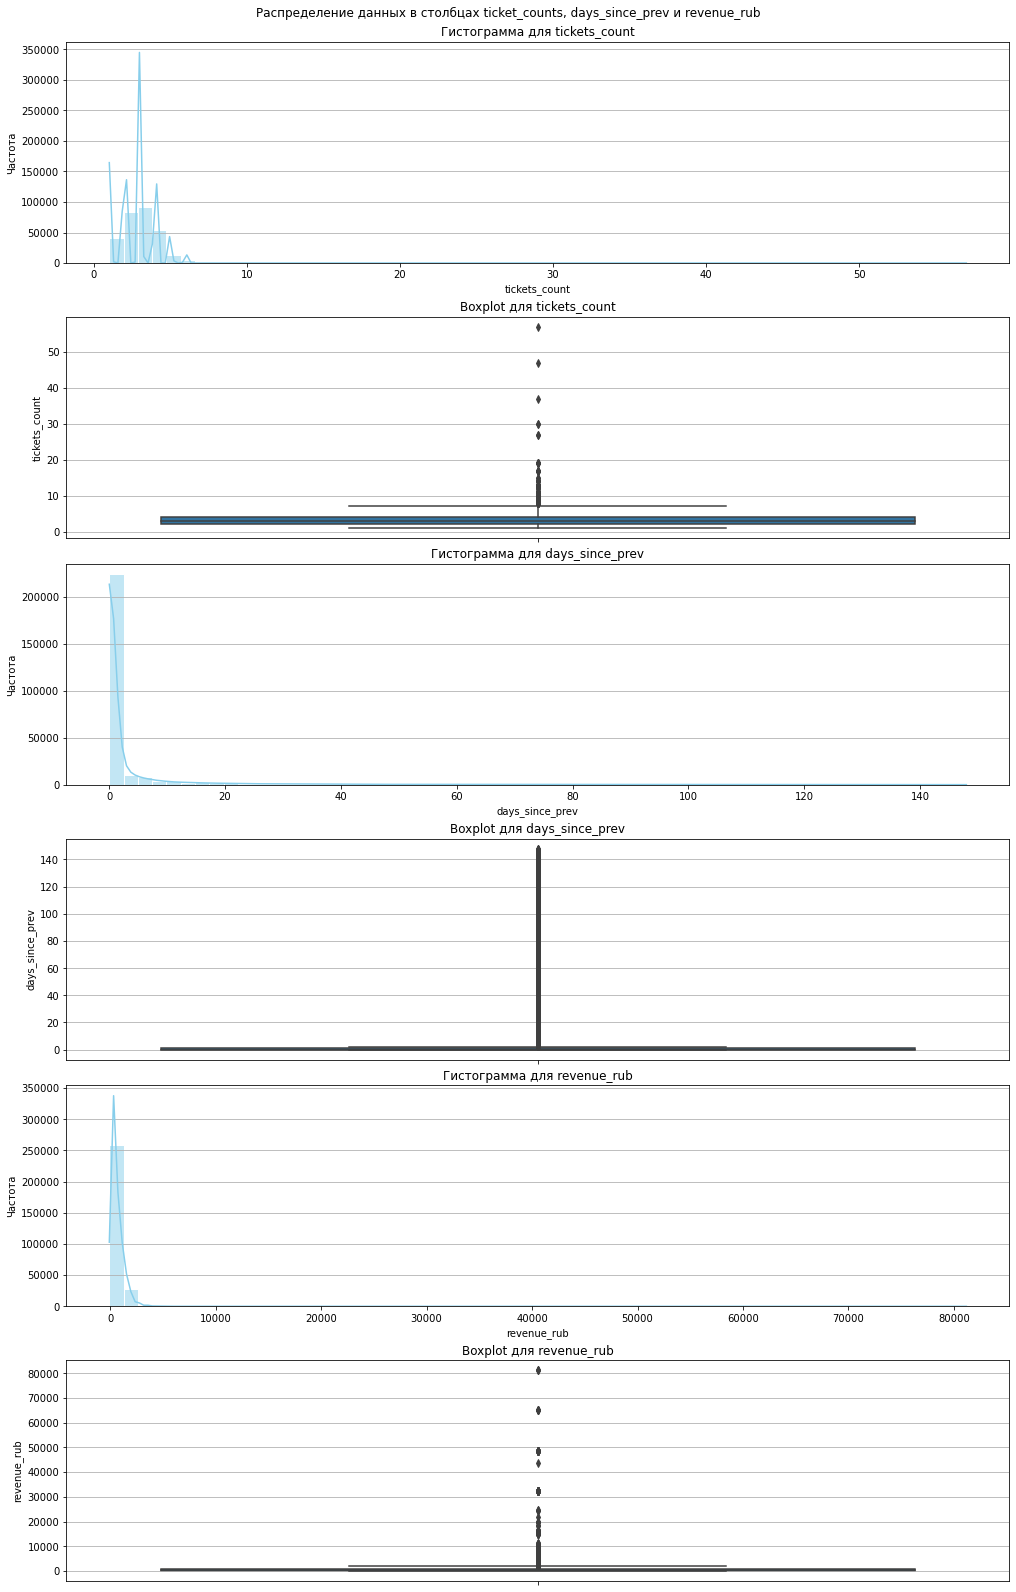

In [27]:
fig, axes = plt.subplots(6, 1, figsize=(14, 22), constrained_layout=True)

for i, (name, values) in enumerate(df[['tickets_count', 'days_since_prev', 'revenue_rub']].items()):
    hist_idx = 2 * i
    box_idx = 2 * i + 1
    
    sns.histplot(data=df, 
                 x=name, 
                 bins=60, 
                 kde=True, 
                 ax=axes[hist_idx], 
                 edgecolor='white', 
                 color='skyblue'
                )
    
    axes[hist_idx].set_title(f'Гистограмма для {name}')
    axes[hist_idx].set_ylabel('Частота')
    axes[hist_idx].grid(axis='y')
    
    sns.boxplot(data=df, y=name, ax=axes[box_idx])
    axes[box_idx].set_title(f'Boxplot для {name}')
    axes[box_idx].grid(axis='y')
    
plt.suptitle('Распределение данных в столбцах ticket_counts, days_since_prev и revenue_rub')
plt.show()

Судя по графмкам для 3х таблиц можно заметить очень много выбросов в значениях, плюс отрицательные значения могут влиять на дальнейший анализ отфильтруем по 99 процентилю

Отфильтровано: 2825
в процентах: 0.97%


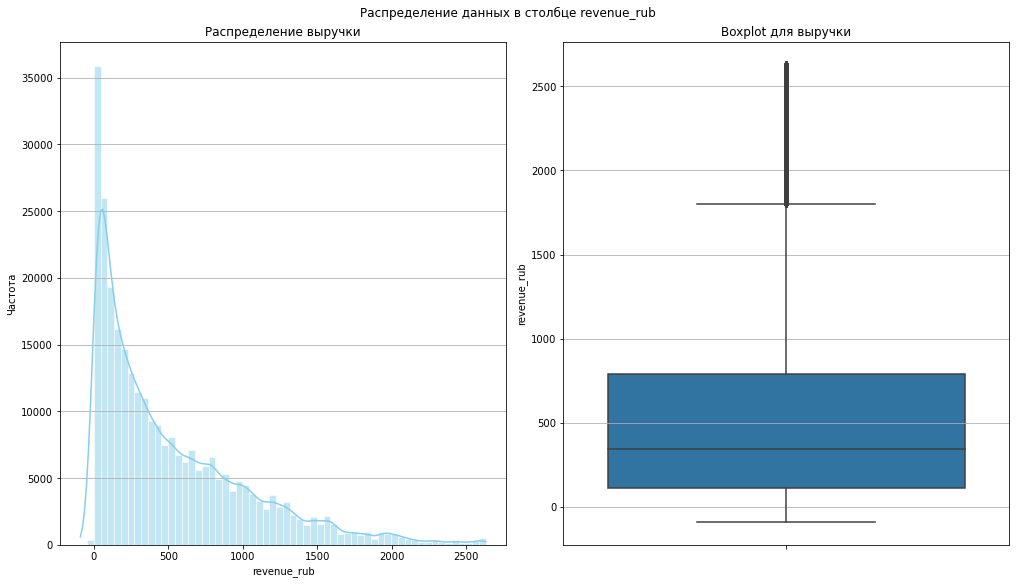

In [28]:
# Зафиксируем количество строк до фильтрации
len_before_filt = df.shape[0]

#Отфильтруем столбец revenue_rub по 99 процентилю
quantile_99 = df['revenue_rub'].quantile(0.99)
df = df.loc[df['revenue_rub'] <= quantile_99]

print(f'Отфильтровано: {len_before_filt - df.shape[0]}')
print(f'в процентах: {((len_before_filt - df.shape[0]) / len_before_filt):.2%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 8), constrained_layout=True)

sns.histplot(data=df, 
             x='revenue_rub', 
             bins=60, 
             kde=True, 
             ax=axes[0], 
             edgecolor='white', 
             color='skyblue')

axes[0].set_title('Распределение выручки')
axes[0].set_ylabel('Частота')
axes[0].grid(axis='y')
    
sns.boxplot(data=df, y='revenue_rub', ax=axes[1])
axes[1].set_title('Boxplot для выручки')
axes[1].grid(axis='y')
    
plt.suptitle('Распределение данных в столбце revenue_rub')
plt.show()

из-за того что `tickets_count` имеет целочисленные значения у нас получилось бимодальное распределение, для этого столбца построим столбчатую диаграмму

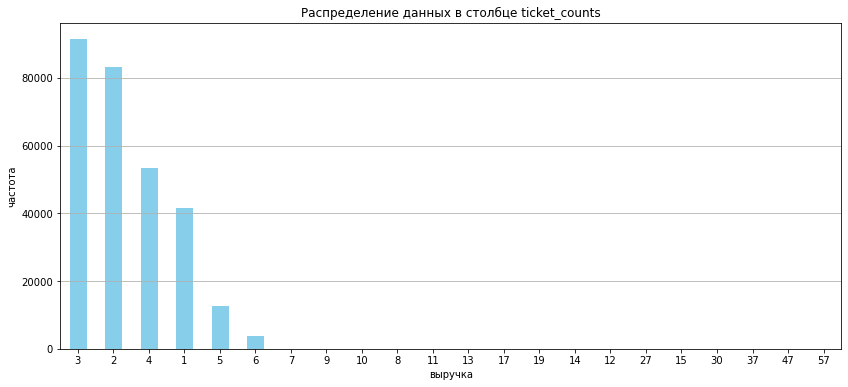

In [29]:
plt.figure(figsize = (14,6))
df['tickets_count'].value_counts().plot(kind='bar', 
                                        x=name, 
                                        rot=0, 
                                        edgecolor='white', 
                                        color='skyblue')
    
plt.title('Распределение данных в столбце ticket_counts')
plt.xlabel('выручка')
plt.ylabel('частота')
plt.grid(axis='y')
plt.show()

осталось проверить отрицательные и нулевые значения в `revenue_rub`и сформировать выводы

In [30]:
# разберемся с отрицательной выручкой
print(f'Количество отрицательной и нулевой выручки: {df.loc[df["revenue_rub"] <= 0].shape[0]}')
print(f'в процентах: {((df.loc[df["revenue_rub"] <= 0].shape[0]) / df.shape[0]):.4%}')

Количество отрицательной и нулевой выручки: 5905
в процентах: 2.0522%


Количество строк подлежащих фильтрации по отрицальной выручки будет составлять **2.05%** от общего числа строк в датафрейме по 99му процентилю. Это приемлемый процент, отфильтруем датафрейм и посчитаем сколько строк удалено в общем после фильтраций и удаления дубликатов

In [31]:
df = df.loc[df["revenue_rub"] > 0]
print(f'количество удаленных строк: {rows_before - df.shape[0]}')
print(f'количество удаленных строк в процентах: {((rows_before - df.shape[0]) / rows_before):.4%}')

print(f'Количество строк в предобработанном датафрейме: {df.shape[0]}')

количество удаленных строк: 8774
количество удаленных строк в процентах: 3.0192%
Количество строк в предобработанном датафрейме: 281837


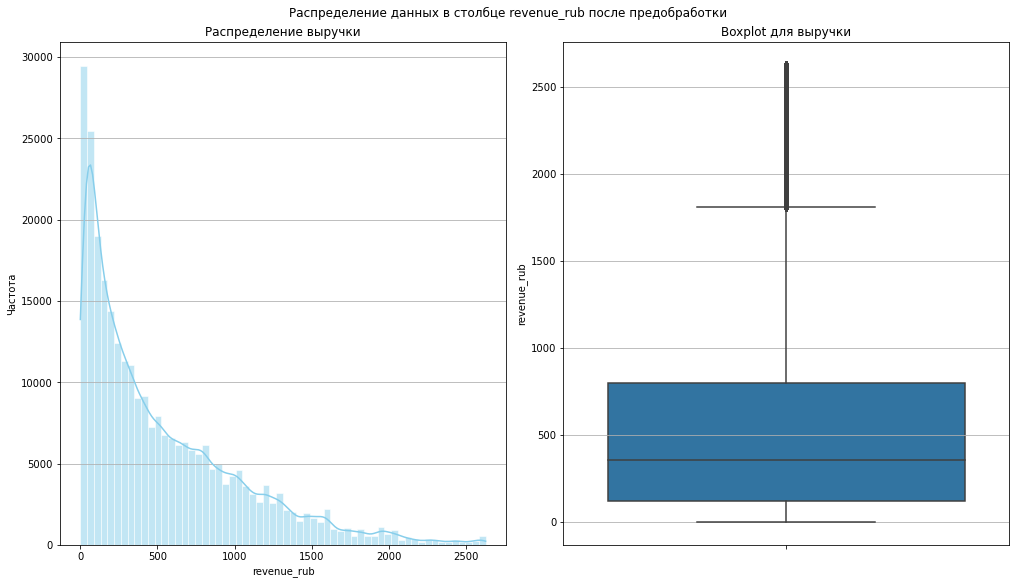

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), constrained_layout=True)

sns.histplot(data=df, 
             x='revenue_rub', 
             bins=60, 
             kde=True, 
             ax=axes[0], 
             edgecolor='white', 
             color='skyblue'
            )

axes[0].set_title('Распределение выручки')
axes[0].set_ylabel('Частота')
axes[0].grid(axis='y')
    
sns.boxplot(data=df, 
            y='revenue_rub', 
            ax=axes[1])

axes[1].set_title('Boxplot для выручки')
axes[1].grid(axis='y')
    
plt.suptitle('Распределение данных в столбце revenue_rub после предобработки')
plt.show()

In [33]:
df.describe()

,order_id,revenue,tickets_count,days_since_prev,event_id,revenue_rub
count,2.818370e+05,281837.000000,281837.000000,260456.000000,281837.000000,281837.000000
mean,4.326630e+06,584.410229,2.744122,3.252246,435694.304030,528.901425
std,2.495782e+06,840.545929,1.157168,11.415837,148104.650189,511.702934
min,1.000000e+00,0.020000,1.000000,0.000000,4436.000000,0.020000
25%,2.169027e+06,125.690000,2.000000,0.000000,354783.000000,122.730000
50%,4.327149e+06,362.440000,3.000000,0.000000,494017.000000,358.350000
75%,6.487968e+06,805.480000,3.000000,1.000000,544944.000000,798.070000
max,8.653108e+06,13784.260000,47.000000,148.000000,592325.000000,2628.421739


Дополним наши наблюдения после отображения графиков и фильтраций

В данных:

 - столбец `revenue_rub` - Среднее **528.90** и медиана **358.35** все еще сильно отличаются, стандартное отклонение уменьшилось с **~875.5** до **511,70**, но все-равно еще большое и большой размах, говорят о выбросах в данных макс значение после фильтрации изменилось с **81174.5** до **2628,4**, что уже ближе к реальности. Из графика распределения видно, что имеется длинный правый хвост, 50% данных находятся в пределах от примерно **122.7** до **798.07** рублей. Для дальнейшего анализа рекомендуется использовать медиану. Дальнейшая чистка от выбросов может удалить значительный кусок данных для анализа
 - столбец `days_since_prev` - среднее значение **3.25** медиана **0** макс значение **148** говорит, что есть выбросы, **75% по 75му процентилю** повторных покупок совершались в пределах 1 дня. График экстремально смещен влево к нулевым значениям с большим правым хвостом. Соответственно гипотеза о том что повторные покупки совершались в основном в пределах 1 дня подтверждается.  
 - столбец `ticket_counts` - мин заказ **1** билет, макс **47**, большой размах, среднее **2,74** и медиана **3,00**. Из графиков видно, что самое большое количество билетов в одном заказе - **3**. Также в большинстве случаев в одном заказе от 2х до 6 билетов, но есть и единичные случаи превышающие эти значения, такие как оптовые закупки с **47** билетами 

### Промежуточные результаты этапа предобработки:

На этом этапе мы сделали:
  - создали новый столбец `revenue_rub`, включающий данные в тенге с конвертацией в рубли
  - провели поиск пропусков. Пропуски не являются аномалией и указывают на пользователей совершивших всего 1 заказ
  - провели поиск явных и неявных дубликатов. **44** (0.02%) дубликата удалено
  - посмотрели на распределение данных категориальных и числовых столбцов:
     - категориальные:
       - всего уникальных клиентов **21933**, причем один из клиентов сделал **10251** заказ
       - **2** типа устройств, с которых делались заказы. В лидерах мобильное устройство с **232457** заказами
       - **2** типа валюты, поэтому мы уже создали доп столбец в рублях
       - **15248** проведенных уникальных мероприятий
       - представлено **7** типов мероприятий, в лидерах концерты - **115265**
       - **36** билетных агентов, лидер `билеты без проблем` - **63502** заказов
       - **81** регион, топ - `каменевский регион` - **91044** заказов
       - **352** города, топ - `глиногорск` - **89432** заказов
       в категориальных данных аномалий не обнаружено, в столбце тип мероприятия есть категория `другое`. В этой категории указаны типы мероприятий не вошедшие в 6 представленных категорий.
     - Числовые:
       - столбец `revenue_rub` - Среднее **528.90** и медиана **358.35** все еще сильно отличаются, стандартное отклонение уменьшилось с **~875.5** до **511,70**, но все-равно еще большое и большой размах, говорят о выбросах в данных макс значение после фильтрации изменилось с **81174.5** до **2628,4**, что уже ближе к реальности. Из графика распределения видно, что имеется длинный правый хвост, 50% данных находятся в пределах от примерно **122.7** до **798.07** рублей. Дальнейшая чистка от выбросов может удалить значительный кусок данных для анализа
       - столбец `days_since_prev` - среднее значение **3.25** медиана **0** макс значение **148** говорит, что есть выбросы,   Для **75% по 75му процентилю** повторных заказов временной интервал между заказами не превышает 1 дня (повторный заказ делается в течении суток). График экстремально смещен влево к нулевым значениям с большим правым хвостом. Соответственно гипотеза о том что повторные заказы совершаются в пределах 1 дня подтверждается. 
       - столбец `ticket_counts` - мин заказ **1** билет, макс **47**, большой размах, среднее **2,74** и медиана **3,00**. Из графиков видно, что самое большое количество билетов в одном заказе - **3**. Также в большинстве случаев в одном заказе от 2х до 6 билетов, но есть и единичные случаи превышающие эти значения, такие как оптовые закупки с **47** билетами 
        
 
- провели фильтрацию данных от выбросов по 99му процентилю и отрицательных, и нулевых значений в столбце `revenue_rub` общее количество удаленных строк после поедобработки: **8774** в процентах: **3.02%** от общего числа строк исходного датафрейма. Что является приемлемым значением
  
На этом можно считать предобработку оконченной и переходить к слежующему этапу

[Назад к оглавлению](#Оглавление)

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас просят построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

#### Задача 3.1: Построение профиля пользователя 
Построить профиль пользователя — для каждого пользователя найти:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- жанр первого посещённого мероприятия;
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее время между заказами.

После этого добавить бинарный признак:

- `is_two` — совершил ли пользователь 2 и более заказа.

---

In [34]:
# Сортируем датафрейм
df_sorted = df.sort_values('order_ts')

# Создаем профиль
user_profile = df_sorted.groupby('user_id').agg(
    first_order = ('order_dt', 'min'),
    last_order = ('order_dt', 'max'),
    first_device = ('device_type_canonical', 'first'),
    first_region = ('region_name', 'first'),
    first_event_type = ('event_type_main', 'first'),
    total_orders = ('order_id', 'count'),
    avg_revenue = ('revenue_rub', 'mean'),
    avg_time_between_orders = ('days_since_prev', 'mean')
)

# Добавляем бинарный столбец для пользователей сделавших более 2х заказов
user_profile['is_two'] = (user_profile['total_orders'] >= 2).astype(int)

display(user_profile.head(10))

,first_order,last_order,first_device,first_region,first_event_type,total_orders,avg_revenue,avg_time_between_orders,is_two
user_id,,,,,,,,,
0002849b70a3ce2,2024-08-20,2024-08-20,mobile,каменевский регион,театр,1,1521.940000,NaN,0
0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,каменевский регион,выставки,2,774.010000,75.000000,1
000898990054619,2024-07-13,2024-10-23,mobile,североярская область,другое,3,767.213333,51.000000,1
00096d1f542ab2b,2024-08-15,2024-08-15,desktop,каменевский регион,театр,1,917.830000,NaN,0
000a55a418c128c,2024-09-29,2024-10-15,mobile,поленовский край,театр,2,61.310000,16.000000,1
000cf0659a9f40f,2024-06-20,2024-06-21,mobile,широковская область,концерты,13,1175.808462,0.083333,1
00147c9209d45d3,2024-06-25,2024-06-25,mobile,каменевский регион,концерты,2,352.945000,0.000000,1
00199a573901564,2024-06-17,2024-06-17,mobile,каменевский регион,концерты,1,588.120000,NaN,0
001e7037d013f0f,2024-07-04,2024-09-29,mobile,златопольский округ,другое,3,326.623333,43.500000,1


Профиль составлен корректно идем дальше

[Назад к оглавлению](#Оглавление)

---

#### Задача 3.2: Поиск аномалий в профиле пользователя 

Используя данные о профилях пользователей, рассчитать:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа.

Изучить статистические показатели:

- по общему числу заказов;
- по среднему количеству дней между покупками.

По результатам оценить данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов?

Если найдутся аномальные значения:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

---

In [35]:
print(f'общее число пользователей в выборке: {user_profile.shape[0]}')
print(f'средняя выручка с одного заказа: {user_profile["avg_revenue"].mean(): .2f}')
print(f'доля пользователей, совершивших 2 и более заказа: {user_profile["is_two"].mean(): .2%}')

общее число пользователей в выборке: 21700
средняя выручка с одного заказа:  551.87
доля пользователей, совершивших 2 и более заказа:  61.67%


In [36]:
user_profile[['total_orders', 'avg_time_between_orders']].describe()

,total_orders,avg_time_between_orders
count,21700.000000,13457.00000
mean,12.987880,15.90167
std,119.752262,22.34165
min,1.000000,0.00000
25%,1.000000,1.00000
50%,2.000000,8.00000
75%,5.000000,20.50000
max,9987.000000,148.00000


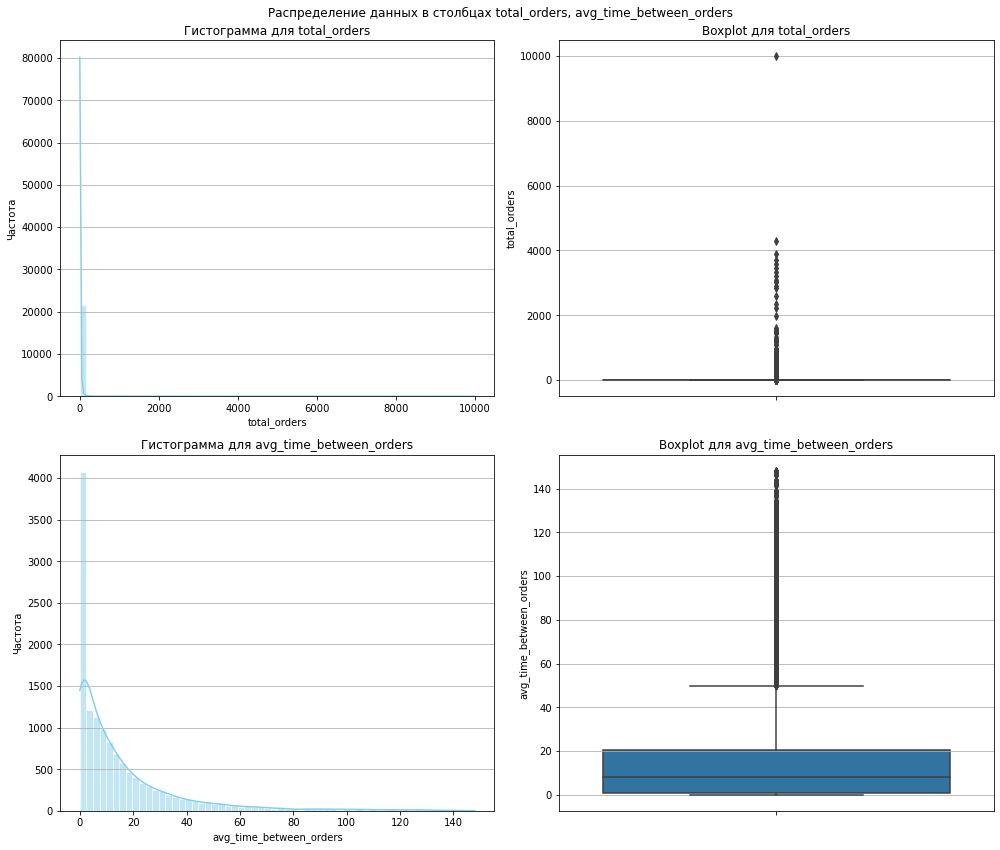

In [37]:
#Построим гимтограммы и боксплоты для статистических данных

fig, axes = plt.subplots(2,2, figsize=(14,12))

for i, (name, value) in enumerate(user_profile[['total_orders', 'avg_time_between_orders']].items()):
    sns.histplot(data=user_profile, 
                 x=name, 
                 bins=60, 
                 kde=True, 
                 ax=axes[i, 0], 
                 edgecolor='white', 
                 color='skyblue'
                )
    
    axes[i, 0].set_title(f'Гистограмма для {name}')
    axes[i, 0].set_ylabel('Частота')
    axes[i, 0].grid(axis='y')
    
    sns.boxplot(data = user_profile, y = name, ax = axes[i, 1])
    axes[i, 1].set_title(f'Boxplot для {name}')
    axes[i,1].grid(axis='y')
    
plt.suptitle('Распределение данных в столбцах total_orders, avg_time_between_orders')
plt.tight_layout()
plt.show()

Из профиля пользователя мы можен наблюдать:
 - общее количество пользователей: **21700** - данных для анализа пользователей достаточно
 - средняя выручка с 1го заказа: **551,87** выглядит корректно
 - доля пользователей совершивших **2** заказа и более - **61,67%** от общего числа - данных для формирования выводов о повторных покупках тоже достаточно
 - Количество заказов обнаружены аномальные данные в **9987** заказов при том что **75%** пользователей имеют **5** заказов, среднее **12.99** и медиана **2**, все это говорит о выбросах, далее определимся по какому процентилю будем фильтровать
 - аналогичная ситуация со средним временем между заказами, перед фильтрацией проверим сколько строк мы рискуем потерять

In [38]:
#Зафиксируем количество строк до фильтрации
user_before = user_profile.shape[0]
print(f'Количество строк до фильтрации: {user_before}')

#Посчитаем сначала 99 процентиль
quant_99_orders = user_profile['total_orders'].quantile(0.99)
quant_99_days = user_profile['avg_time_between_orders'].quantile(0.99)

orders_to_del = user_profile.loc[user_profile['total_orders'] >= quant_99_orders]
print(f'количество строк более 99 процентиля для orders: {orders_to_del.shape[0]}')
print(f'Доля строк по orders для удаления: {((user_before - (user_before - orders_to_del.shape[0])) / user_before): .2%}')
print(f'99й процентиль orders: {quant_99_orders}')
print()

days_to_del = user_profile.loc[user_profile['avg_time_between_orders'] >= quant_99_days]
print(f'количество строк более 99 процентиля для days: {days_to_del.shape[0]}')
print(f'доля строк для удаления: {((user_before - (user_before - days_to_del.shape[0])) / user_before): .2%}')
print(f'99й процентиль days: {quant_99_days}')
print()


# Посчитаем по 95 процентилю
quant_95_orders = user_profile['total_orders'].quantile(0.95)
quant_95_days = user_profile['avg_time_between_orders'].quantile(0.95)

orders_to_del_95 = user_profile.loc[user_profile['total_orders'] >= quant_95_orders]

print(f'количество строк более 95 процентиля для orders: {orders_to_del_95.shape[0]}')
print(f'Доля строк по orders для удаления: {((user_before - (user_before - orders_to_del_95.shape[0])) / user_before): .2%}')
print(f'95й процентиль orders: {quant_95_orders}')
print()

days_to_del_95 = user_profile.loc[user_profile['avg_time_between_orders'] >= quant_95_days]

print(f'общее количество строк более 95 процентиля: {days_to_del_95.shape[0]}')
print(f'количество строк более 99 процентиля для days: {((user_before - (user_before - days_to_del_95.shape[0])) / user_before): .2%}')
print(f'95й процентиль days: {quant_95_days}')

Количество строк до фильтрации: 21700
количество строк более 99 процентиля для orders: 217
Доля строк по orders для удаления:  1.00%
99й процентиль orders: 150.0099999999984

количество строк более 99 процентиля для days: 136
доля строк для удаления:  0.63%
99й процентиль days: 113.0

количество строк более 95 процентиля для orders: 1103
Доля строк по orders для удаления:  5.08%
95й процентиль orders: 31.0

общее количество строк более 95 процентиля: 677
количество строк более 99 процентиля для days:  3.12%
95й процентиль days: 61.5


Как можно заметить выбросы по столбцу orders также включают и выбросы по дням, поэтому:

По 99му процентилю мы рискуем потерять около **1.63%** данных если это не одни и теже строки. 99й квантиль **150** по заказам и **113** по дням уберет экстремальные значения
 
По 95му процентилю мы потеряем около **8.2% данных**. это уже большое количество данных, как и вариант по заказам 99й, по дням 95й макс процент 4.12% что тоже многовато

После анализа, зафиксируем фильтрацию по 99му процентилю

In [39]:
user_profile = user_profile.loc[(user_profile['total_orders'] <= quant_99_orders) & 
                               (
                                   (user_profile['avg_time_between_orders'] <= quant_99_days) |
                                   (user_profile['avg_time_between_orders'].isna())
                               )
]

print(f'количество отфильтрованных строк: {user_before - user_profile.shape[0]}')
print(f'Доля отфильтрованных строк: {((user_before - user_profile.shape[0]) / user_before): .2%}')
print()


количество отфильтрованных строк: 349
Доля отфильтрованных строк:  1.61%



Так как фильтрация в pandas помечает данные с пропусками как false и убирает доп строки, чтобы перестраховаться в столбце `avg_time_between_orders` ввели условие, чтобы остались строки с пропусками

проверка показала, что фильтрация прошла успешно удалено 349 строк (1.61%)

посмотрим на изменения в стат данных

In [40]:
user_profile.describe()

,total_orders,avg_revenue,avg_time_between_orders,is_two
count,21351.000000,21351.000000,13108.000000,21351.000000
mean,6.431081,552.029061,15.037112,0.610697
std,14.019268,433.759088,19.552372,0.487604
min,1.000000,0.070000,0.000000,0.000000
25%,1.000000,217.145600,1.296135,0.000000
50%,2.000000,472.770000,8.166667,1.000000
75%,5.000000,775.041000,20.250000,1.000000
max,150.000000,2628.421739,113.000000,1.000000


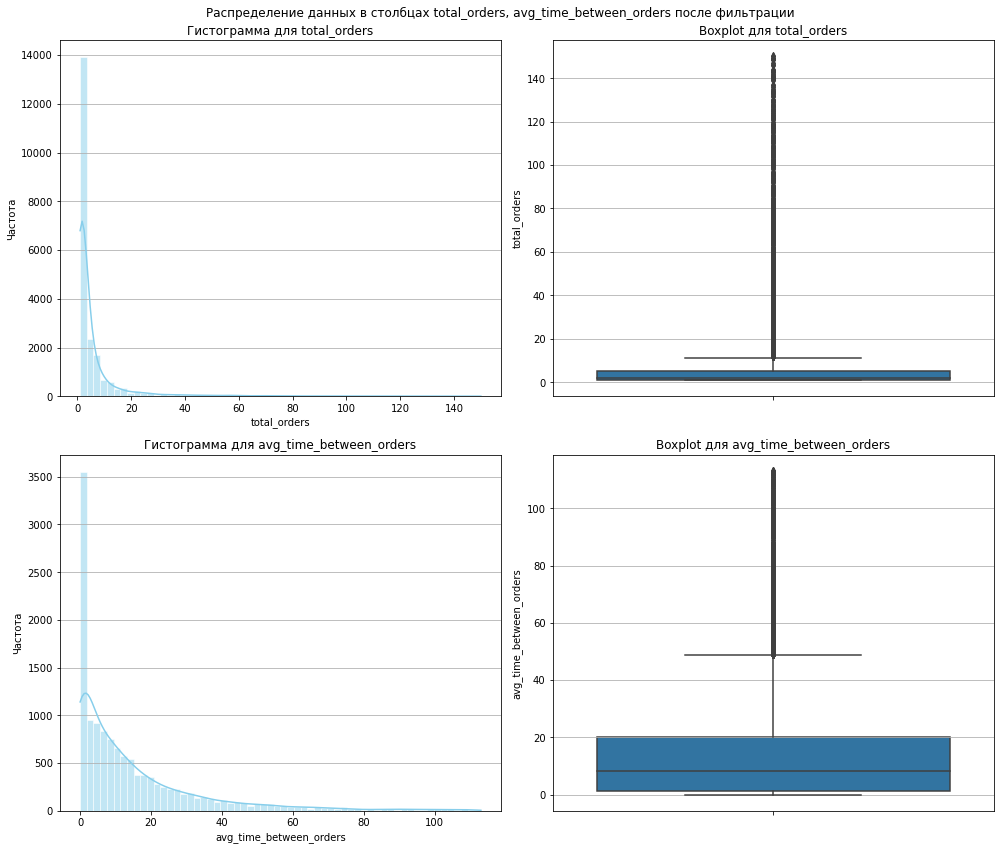

In [41]:
#Построим гимтограммы и боксплоты для статистических данных

fig, axes = plt.subplots(2,2, figsize=(14,12))

for i, (name, value) in enumerate(user_profile[['total_orders', 'avg_time_between_orders']].items()):
    sns.histplot(data=user_profile, 
                 x=name, 
                 bins=60, 
                 kde=True, 
                 ax=axes[i, 0], 
                 edgecolor='white', 
                 color='skyblue'
                )
    
    axes[i, 0].set_title(f'Гистограмма для {name}')
    axes[i, 0].set_ylabel('Частота')
    axes[i, 0].grid(axis='y')
    
    sns.boxplot(data = user_profile, y = name, ax = axes[i, 1])
    axes[i, 1].set_title(f'Boxplot для {name}')
    axes[i,1].grid(axis='y')
    
    
plt.suptitle('Распределение данных в столбцах total_orders, avg_time_between_orders после фильтрации')
plt.tight_layout()
plt.show()

Изменения после фильтрации:
- общее количество пользователей: **21700** уменьшилось до **21351** все еще достаточное количество для анализа
- средняя выручка с 1го заказа: **551,87** увеличилась, но не значительно до **552.03** выглядит корректно
- Макс количество заказов уменьшилось с **9987** до **150** заказов, **75%** пользователей с **5** заказами не изменились, среднее **12.99** уменьшилось до **6.43** и медиана **2**, после фильтрации выглядит более оптимально и правдоподобно для анализа
- время между заказами - макс время уменьшилось со **148** дней до **113**, среднее время между заказами изменилось с **15.9** до **15.04**
 
На этом нормализацию данных можно остановить, дальнейшие действия могут привести к большой потере данных для анализа

Теперь можно приступить к следующему этапу

[Назад к оглавлению](#Оглавление)

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа.

#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

##### Задача 4.1.1 Изучение распределения пользователей по признакам 

Изучить распределение пользователей по признакам.

- Сгруппировать пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа.
- Подсчитать общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. 
- Ответить на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---

In [42]:
for col in ['first_event_type', 'first_device', 'first_region']:
    print(f'Количество пользователей по {col}:')
    display(user_profile[col].value_counts())
    print(f'Доля пользователей по {col}:')
    display((user_profile[col].value_counts() / user_profile.shape[0] * 100).round(4))

Количество пользователей по first_event_type:


концерты    9541
другое      5195
театр       4231
стендап     1113
спорт        764
выставки     410
ёлки          97
Name: first_event_type, dtype: int64

Доля пользователей по first_event_type:


концерты    44.6864
другое      24.3314
театр       19.8164
стендап      5.2129
спорт        3.5783
выставки     1.9203
ёлки         0.4543
Name: first_event_type, dtype: float64

Количество пользователей по first_device:


mobile     17702
desktop     3649
Name: first_device, dtype: int64

... (2 outputs left out)

Количество пользователей по first_region:


каменевский регион           6918
североярская область         3759
широковская область          1228
озернинский край              676
малиновоярский округ          524
шанырский регион              460
травяная область              459
светополянский округ          457
речиновская область           441
яблоневская область           410
верхоречная область           380
лугоградская область          360
медовская область             355
серебринская область          332
тепляковская область          322
солнечнореченская область     295
солнечноземская область       285
горицветская область          244
глиногорская область          218
зоринский регион              213
заречная область              205
лесодальний край              196
речицкий регион               189
каменноярский край            169
ветренский регион             153
травиницкий округ             129
берёзовская область           108
каменноозёрный край           106
малиновая область             105
боровлянский к

Доля пользователей по first_region:


каменевский регион           32.4013
североярская область         17.6057
широковская область           5.7515
озернинский край              3.1661
малиновоярский округ          2.4542
шанырский регион              2.1545
травяная область              2.1498
светополянский округ          2.1404
речиновская область           2.0655
яблоневская область           1.9203
верхоречная область           1.7798
лугоградская область          1.6861
медовская область             1.6627
серебринская область          1.5550
тепляковская область          1.5081
солнечнореченская область     1.3817
солнечноземская область       1.3348
горицветская область          1.1428
глиногорская область          1.0210
зоринский регион              0.9976
заречная область              0.9601
лесодальний край              0.9180
речицкий регион               0.8852
каменноярский край            0.7915
ветренский регион             0.7166
травиницкий округ             0.6042
берёзовская область           0.5058
к

Построим графики распределения количества пользователей по сегментам, для регионов оставим топ 10 для наглядности, так как остальные распределяются почти равномерно от **1 (~0.005%)** до **410 (1.9%)** пользователей на регион. Это очень маленбкая доля от общего числа пользователей

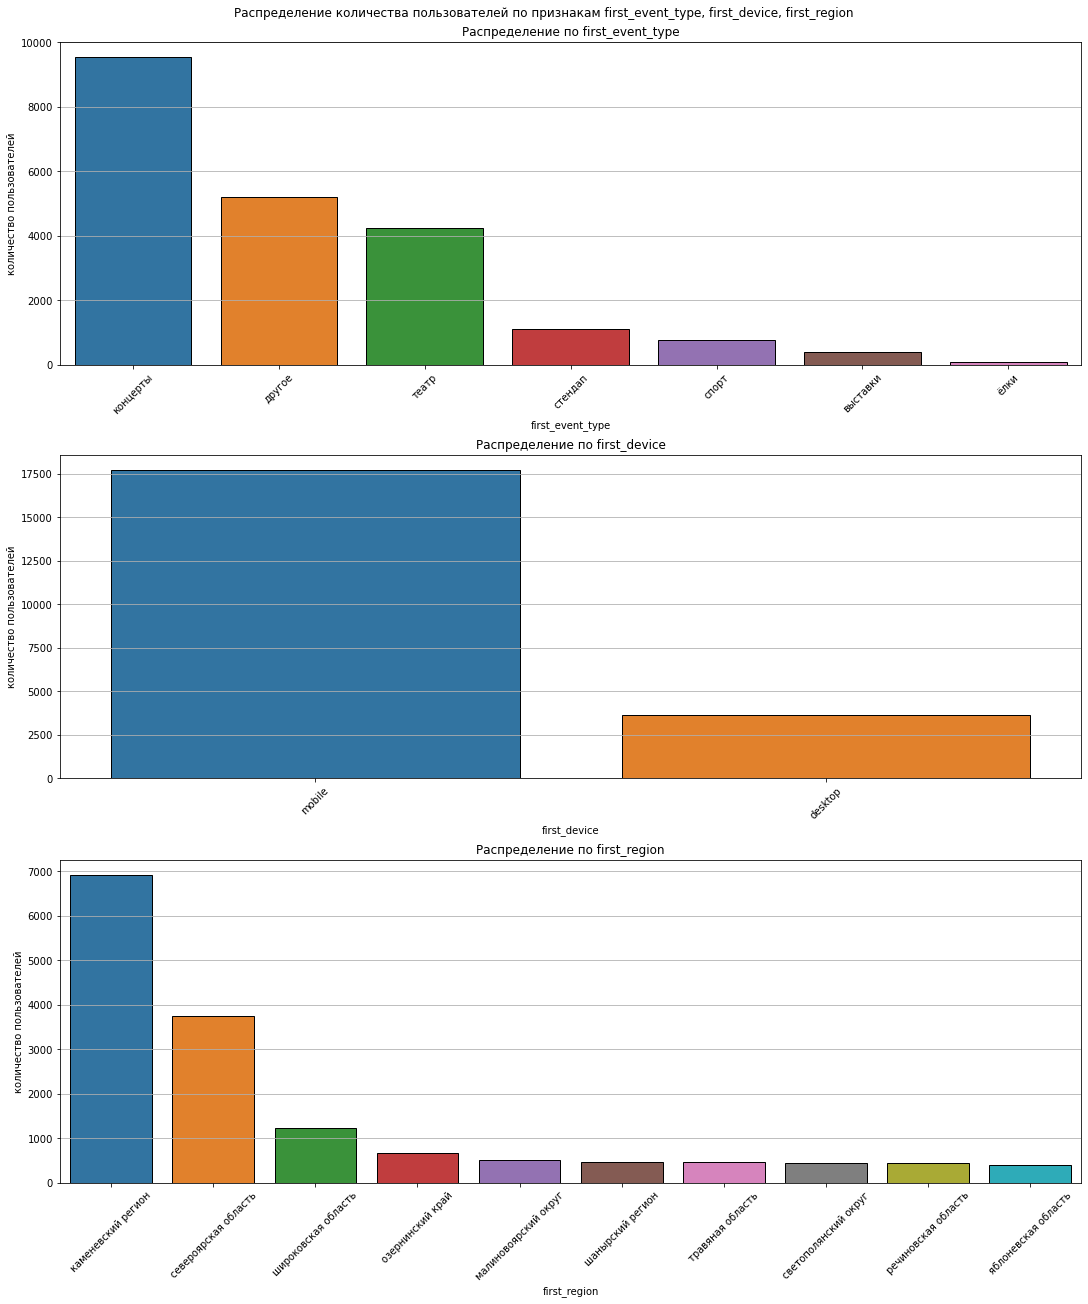

In [43]:
fig, axes = plt.subplots(3,1, figsize=(15,18), constrained_layout=True)

for ax, name in zip(axes, ['first_event_type', 'first_device', 'first_region']):
    counts = user_profile[name].value_counts().head(10)
    
    sns.barplot(data=user_profile,
               x=counts.index,
               y=counts.values,
               ax=ax,
               edgecolor='black')
    ax.set_title(f'Распределение по {name}')
    ax.set_xlabel(f'{name}')
    ax.set_ylabel('количество пользователей')
    ax.tick_params(axis='x', labelrotation = 45)
    ax.grid(axis='y')
plt.suptitle('Распределение количества пользователей по признакам first_event_type, first_device, first_region')
plt.show()

**Промежуточные выводы** 
Из данных и графиков по сегментам мы можем четко выделить, что:
 - **по первому типу события**. Очень сильно выделяются 2 типа: `концерты` - **9541 (44,7%)**, `театр` **4231 (19,8%). 3й тип `другое` с 5195 (24,33%)** не может сказать что-либо так как в эту категорию входит множество других типов мероприятий, которые не вошли в другие представленные категории, остальные категории варьируются от `елки` - **97(0.45%)** до `стендап` **1113 (5.21%)**
 - **по типу платформы с которого делался первый заказ**. В данных представлено 2 типа `мобильные устройства` и `ПК`. С явным преимуществом выделяются `мобильные устройства` с **17702 (82.9%)** против `ПК` с **3649 (17.1%)**
 - **по первому региону**. Очень сильно по отношению к остальным регионам выделяются 3: `Каменевский регион`, `североярская область` и `широковская область` с **6918 (32.4%)**, **3759 (17.6%)**, **1228 (5.75%)** соответственно. остальные регионы варьируются с **1 (0.005%)** пользователя до **676 (3.17%)** пользователей
 
Из этих данных вырисовываются "точки входа": 
 - Пользователи больше всего в первый раз заказывают билеты на `концерты`, что является вполне корректным, концертные события имеют высокую популярность, и в `театр` для культурного слоя пользователей. 
 - Первые заказы делались с `мобильных устройств`, что характерно для текущего времени, когда люди совершают быстрые покупки через приложения иногда даже "на ходу". 
 - Первые регионы `Каменевский регион`, `североярская область` и `широковская область`. Это может быть связано с плотностью населения и активностью.

[Назад к оглавлению](#Оглавление)

---

##### Задача 4.1.2 Анализ возврата пользователей 

Проанализировать возвраты пользователей:

- Для каждого сегмента вычислить долю пользователей, совершивших два и более заказа.
- Ответить на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?
    
---

In [44]:
#Посчитаем долю долю пользователей, совершивших два и более заказа для каждого сегмента.
print(f'количество пользователей, совершивших два и более заказа: {user_profile["is_two"].sum()}')
print(f'Доля пользователей, совершивших два и более заказа: {user_profile["is_two"].mean():.2%}')

количество пользователей, совершивших два и более заказа: 13039
Доля пользователей, совершивших два и более заказа: 61.07%


In [45]:
# Напишем цмкл для подсчета долей по сегментам
for col in ['first_event_type', 'first_device', 'first_region']:
    print(f'Доля пользователей, совершивших два и более заказа по {col}:')
    
    # Добавлен столбец count
    display(
        (
            user_profile.groupby(col)['is_two']
            .agg(count = 'count', mean = lambda x: x.mean() * 100)
        )
        .round(4)
        .sort_values( by = 'count',ascending = False)
    )

Доля пользователей, совершивших два и более заказа по first_event_type:


,count,mean
first_event_type,,
концерты,9541,61.5554
другое,5195,59.2300
театр,4231,63.2475
стендап,1113,60.7367
спорт,764,54.9738
выставки,410,63.9024
ёлки,97,56.7010


Доля пользователей, совершивших два и более заказа по first_device:


,count,mean
first_device,,
mobile,17702,60.6203
desktop,3649,63.2502


Доля пользователей, совершивших два и более заказа по first_region:


,count,mean
first_region,,
каменевский регион,6918,61.6363
североярская область,3759,63.8468
широковская область,1228,64.3322
озернинский край,676,55.0296
малиновоярский округ,524,55.5344
шанырский регион,460,69.1304
травяная область,459,61.4379
светополянский округ,457,65.4267
речиновская область,441,63.9456


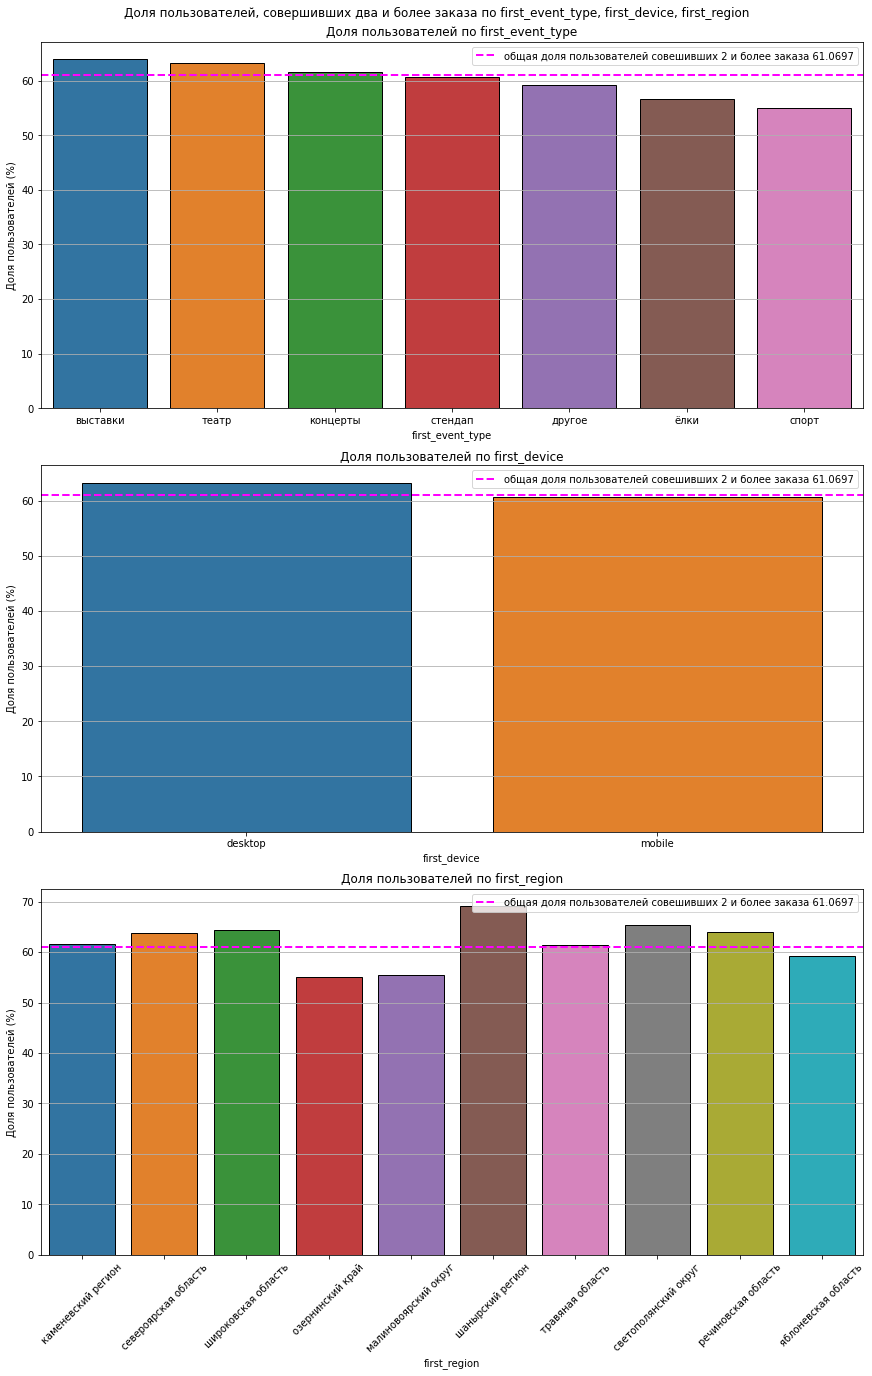

In [46]:
# Создаем сетку для графиков
fig, axes = plt.subplots(3,1, figsize=(12,19), constrained_layout=True)

# Создаем цикл для формирования графиков по всем 3м столбцам
for ax, name in zip(axes, ['first_event_type', 'first_device', 'first_region']):
    
    user_share = round((user_profile["is_two"].mean() * 100), 4)
    
    # Считаем доли по сегментам. Исправлено
    user_profile_groupped =(
         user_profile.groupby(name)['is_two']
        .agg(share = lambda x: x.mean() * 100, count = 'count')
        .round(4)
        .reset_index()
    )
    
    # Добавлено условие сортировки по count только для региона
    if name == 'first_region':
        user_profile_groupped = user_profile_groupped.sort_values(by='count', ascending=False).head(10)
    else:
        user_profile_groupped = user_profile_groupped.sort_values(by='share', ascending=False)
    
        
    # Рисуем столбчатые графики для каждого сегмента
    sns.barplot(data=user_profile_groupped,
               x=name,
               y='share',
               ax=ax,
               edgecolor='black',
               )
    ax.axhline(user_share,
               color='magenta',
               linestyle='--',
               linewidth=2,
               label=f'общая доля пользователей совешивших 2 и более заказа {user_share}'
               )
    
    # Настраиваем графики, легенду выносим за график, чтобы не загромождало сам график
    ax.set_title(f'Доля пользователей по {name}')
    ax.set_xlabel(f'{name}')
    ax.set_ylabel('Доля пользователей (%)')
    ax.legend(loc = 'upper right')
    if name == 'first_region':
        ax.tick_params(axis='x', labelrotation = 45)
    
    ax.grid(axis='y')    

# Общий заголовок для всех графиков
plt.suptitle('Доля пользователей, совершивших два и более заказа по first_event_type, first_device, first_region')
plt.show()

 **Промежуточные выводы**:
 
 - **По типу мероприятия** - по 4м типам мероприятий из 7, доля сделавших 2 и более заказа примерно равна общей доле пользователей сделавших 2 и более заказа равной **61.07%** и варьируется от **60.74%** у `стендапа` до **63.90%** у `выставок`. Другие 3 ниже общей доли это `другое`, `елки`, `спорт` - **59.2%**, **56.7%**, **54.97%**. 2а лидера по количеству пользователей из предыдущей задачи `концерты` и `театры` имеют **61.56%** и **63.25%**
 - **типу устройств** - доля пользователей сделавших первые заказы c `ПК` и имеют 2 и более заказа в общем, составляет **63.25%** и немного превосходит `мобильные устройства` - **60.62%**, что практически недалеко от общей доли. Таким образом тип устройства вряд ли влияет на количество заказов
 - **Регион** - в данных диапазон 26 регионов превышают общую долю в 61,07%, лидер на графике со **100%** `вурхозерский край` далеко не показатель этот регион с наименьшим числом пользователей, а вот лидеры по количеству пользователей `Каменевский регион`, `североярская область` и `широковская область` имеют **61.63%**, **63.85%** и **64.33%**, что выше общей средней доли
 
 По долям заметно выраженных причин возврата не выявлено все показания варьируются вокруг общей доли пользователя в **61.07%** 

[Назад к оглавлению](#Оглавление)

---

##### Задача 4.1.3. Проверка продуктовых гипотез

Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

In [47]:
# Гипотеза 1
sport_users = user_profile.loc[user_profile['first_event_type'] == 'спорт']['is_two'].mean()
concert_users = user_profile.loc[user_profile['first_event_type'] == 'концерты']['is_two'].mean()

compare = 'спорт' if sport_users > concert_users else 'концерт' if concert_users > sport_users else 'равны'
print(f'''Доля возвратов - спорт: {sport_users: .2%} 
доля возвратов концерты: {concert_users: .2%}
Возвратов больше у: {compare}
     ''')


Доля возвратов - спорт:  54.97% 
доля возвратов концерты:  61.56%
Возвратов больше у: концерт
     


**Выводы по гипотезе 1:**

**Гипотеза 1 не подтвердилась**, наоборот возвратов больше у тех кто первый раз оформил заказ на концерты 

In [48]:
# Гипотеза 2
region_compare = user_profile.groupby('first_region')['is_two'].agg(['count', 'mean'])
region_compare['mean'] = region_compare['mean'] * 100
print('Количество и доля возвратов по регионам:')
print(region_compare.sort_values(by='count', ascending=False))

Количество и доля возвратов по регионам:
                           count        mean
first_region                                
каменевский регион          6918   61.636311
североярская область        3759   63.846768
широковская область         1228   64.332248
озернинский край             676   55.029586
малиновоярский округ         524   55.534351
шанырский регион             460   69.130435
травяная область             459   61.437908
светополянский округ         457   65.426696
речиновская область          441   63.945578
яблоневская область          410   59.268293
верхоречная область          380   58.157895
лугоградская область         360   56.388889
медовская область            355   58.028169
серебринская область         332   55.722892
тепляковская область         322   59.316770
солнечнореченская область    295   58.305085
солнечноземская область      285   59.649123
горицветская область         244   66.393443
глиногорская область         218   53.669725
зоринский реги

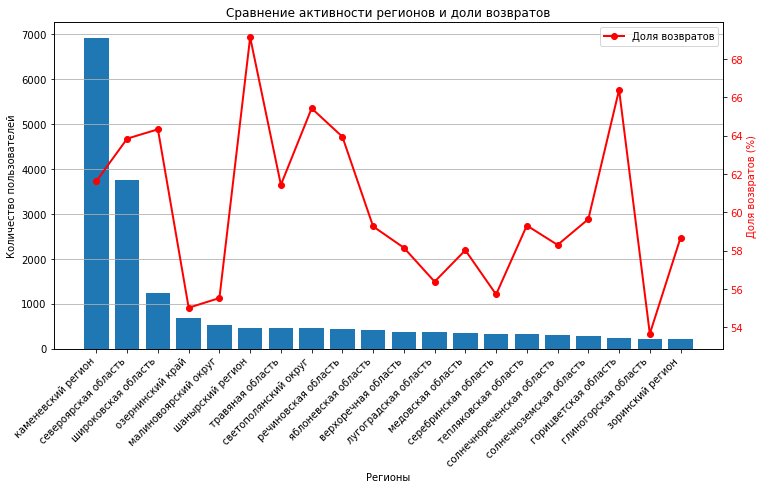

In [49]:
# Подготовим данные для графика
region_compare = region_compare.sort_values(by='count', ascending=False).head(20)

# Задаем сетку для графика
fig, ax1 = plt.subplots(figsize=(12, 6))

# CТроим первый график - столбчатую диаграмму
ax1.bar(
    data=region_compare,
    x=region_compare.index,
    height=region_compare['count']
)
# Настраиваем график
ax1.set_xlabel('Регионы')
ax1.set_ylabel('Количество пользователей')
ax1.grid(axis='y')
ax1.set_xticks(range(len(region_compare.index))) # Уберем ошибку Fixed Locator
ax1.set_xticklabels(region_compare.index, rotation=45, ha='right') # настриваем подписи оси x

# Создадим вторую ось для долей
ax2 = ax1.twinx()

# Строим линию долей возврата по регионам
ax2.plot(
    region_compare.index,
    region_compare['mean'],
    color='red',
    linewidth=2,
    marker='o',
    label='Доля возвратов'
)
# Настраиваем подписи и ось для второго графика 
ax2.set_ylabel('Доля возвратов (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')


plt.legend()
plt.title('Сравнение активности регионов и доли возвратов')
plt.show()


**Выводы по гипотезе 2:**

Судя по графику четко видно хаотичное поведение линии доли возвратов, соответственно гипотеза того, что доля возвратов с увеличением активности увеличивается не подтверждается, в этом случае линия приближенно была бы убывающей прямой слева направо. В нашем случае это не так.

**Гипотеза 2 опровергнута**

[Назад к оглавлению](#Оглавление)

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучить количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

---

**Задача 4.2.1.** Проследить связь между средней выручкой сервиса с заказа и повторными заказами.

- Построить сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответить на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

---

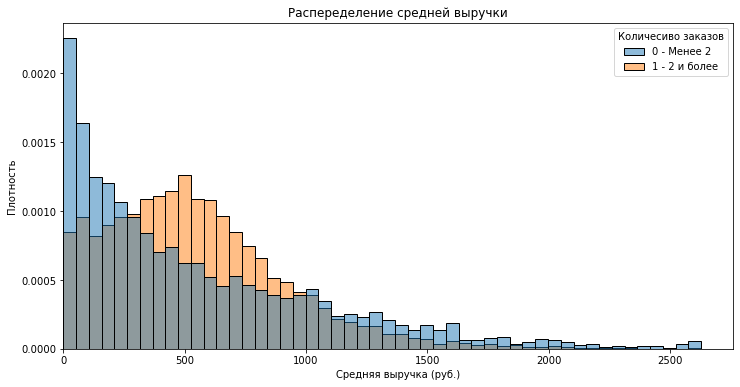

In [50]:
# Построим графики плотности распределения для обоих групп
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=user_profile,
    x='avg_revenue',
    hue='is_two',
    bins=50,
    alpha=0.5,
    stat='density',
    common_norm=False, # Добавлено
    edgecolor='black',
    )

ax.get_legend().set_title('Количесиво заказов')
ax.get_legend().get_texts()[0].set_text('0 - Менее 2')
ax.get_legend().get_texts()[1].set_text('1 - 2 и более')
plt.title('Распеределение средней выручки')
plt.xlabel('Средняя выручка (руб.)')
plt.ylabel('Плотность')
plt.xlim(left=0)

plt.show()

In [51]:
# Посчитаем стат данные для обоих групп
user_profile.groupby('is_two')['avg_revenue'].agg(['sum', 'min', 'max', 'mean', 'median']).round(2)

,sum,min,max,mean,median
is_two,,,,,
0,4594815.03,0.07,2628.42,552.79,388.81
1,7191557.46,0.35,2628.42,551.54,503.16


Условимся, что `первая группа` - меньше 2х заказов, `Вторая группа` - 2 заказа и более.

Диапазон у `первой группы` от **~0** до **~400**. с пиком в районе **~0**

Диапазон `второй группы` от **~300** до **~800** с пиком в районе **~500**

На графике видно, что пик плотности `первой группы` смещается влево ближе к нулевым значениям, значит пользователи с 1м заказом совершают более мелкие по цене покупки, чем `вторая группа`, также имеет длинный правый хвост с редкими дорогими заказами. Это сравнивает среднюю этой группы **552.79** со средним `второй группы` **551.54**. Медиана у `первой группы` **388.81** меньше чем у `второй` **503.16**, что подтверждает гипотезу. 

У `второй группы` более стабильная и высокая медианная выручка, по сравнению с `первой группой`, приносящая больший вклад в общую сумму выручки.

Различия скорей носят структурированный характер, а не в средней или максимальной выручке, которая тоже идентична.

[Назад к оглавлению](#Оглавление)

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучить временные параметры, связанные с первым заказом пользователей, а именно день недели первой покупки.

---

**Задача 4.3.1.** Проанализировать, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделить день недели.
- Для каждого дня недели подсчитать общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответить на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---

In [52]:
user_profile['week_day'] = user_profile['first_order'].dt.day_name()

day_stat = user_profile.groupby('week_day')['is_two'].agg(['count', 'mean'])
day_stat['mean'] = day_stat['mean'] * 100
print('Количество и доля возвратов по дням недели:')
print(day_stat.sort_values(by='mean', ascending=False))

Количество и доля возвратов по дням недели:
           count       mean
week_day                   
Saturday    3275  62.595420
Monday      2879  62.417506
Wednesday   3025  61.884298
Tuesday     3137  61.523749
Sunday      2739  59.948886
Friday      3210  59.719626
Thursday    3086  59.332469


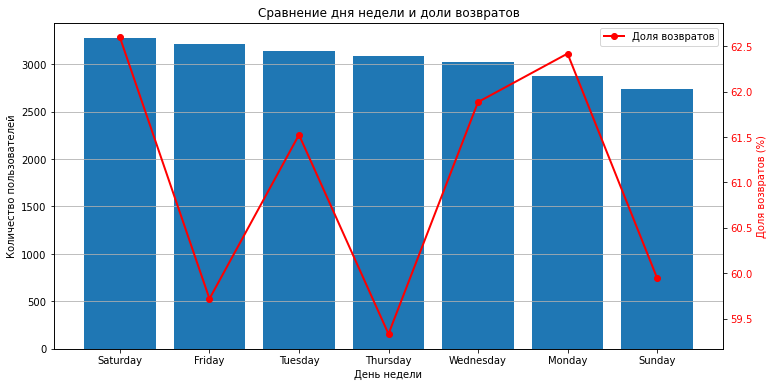

In [53]:
# Подготовим данные для графика
day_stat = day_stat.sort_values(by='count', ascending=False)

# Задаем сетку для графика
fig, ax1 = plt.subplots(figsize=(12, 6))

# CТроим первый график - столбчатую диаграмму
ax1.bar(
    data=day_stat,
    x=day_stat.index,
    height=day_stat['count']
)
# Настраиваем график
ax1.set_xlabel('День недели')
ax1.set_ylabel('Количество пользователей')
ax1.grid(axis='y')

# Создадим вторую ось для долей
ax2 = ax1.twinx()

# Строим линию долей возврата по регионам
ax2.plot(
    day_stat.index,
    day_stat['mean'],
    color='red',
    linewidth=2,
    marker='o',
    label='Доля возвратов'
)
# Настраиваем подписи и ось для второго графика 
ax2.set_ylabel('Доля возвратов (%)', color = 'red')
ax2.tick_params(axis='y', labelcolor='red')


plt.legend()
plt.title('Сравнение дня недели и доли возвратов')
plt.show()

По дням недели количество пользователей находится в диапазоне от **2739** в воскресенье до **3275** в субботу

Максимальные значения по возврату приходится на `субботу` и `понедельник`  **3275 (~62.6%)** и **2879 (62.4%)** соответственно.

Отсюда можно сделать вывод, что большее число пользователей покупают билеты на мероприятия в `субботу` и имеют более высокий возврат, потому что `суббота` это выходной и у работающих людей это более спокойный день недели для обдуманного планирования следующей недели. В `понедельник` тоже высокий возврат, но с меньшим количеством пользователей, так как это первый день недели на работе, неделя может быть еще не распланирована и пока еще есть время на планирование похода на мероприятие на конец недели.

Самые низкие возвраты в `четверг` **3086 (59.3%)** и `пятницу` **3210 (59.7%)**, это конец рабочей недели и в эти дни люди часто покупают билеты спонтанно и единоразово перед выходными. Поэтому большое количество пользователей и малый процент возврата. 

В `воскресенье` наблюдается самое минимальное количество пользователей, а возврат **59.95%** находиться на одном низком уровне с `четвергом` и `пятницей`. Последний день выходных чаще всего занимает подготовка к рабочей неделе или решение домашних проблем

**Вывод:** Метрики возврата различаются в зависимости от дня недели

[Назад к оглавлению](#Оглавление)

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучить, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок.

---

**Задача 4.4.1:** Провести корреляционный анализ:
- Рассчитать коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`).
- Проанализировать полученные результаты. Если полученные значения будут близки к нулю, проверить разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделить сегменты пользователей по полю `total_orders`, а затем повторить корреляционный анализ. Выделить такие сегменты:
    - 1 заказ;
    - 2 заказа;
    - от 3 до 4 заказов (оба значения включительно);
    - от 5 и выше.
- Визуализировать результат корреляции с помощью тепловой карты.
- Ответить на вопрос: какие признаки наиболее связаны с количеством заказов?

---

In [54]:
# Добавлен параметр interval_cols
correlation_matrix = user_profile.phik_matrix(interval_cols=['total_orders', 'avg_revenue', 'avg_time_between_orders'])

print('Корреляционная матрица с коэффициентом phi_k для количества заказов:')
correlation_matrix.loc[correlation_matrix.index != 'total_orders'][['total_orders']].sort_values(by='total_orders', ascending=False)

Корреляционная матрица с коэффициентом phi_k для количества заказов:


,total_orders
first_order,0.427122
last_order,0.419658
avg_time_between_orders,0.343408
is_two,0.322099
avg_revenue,0.226611
first_region,0.125048
week_day,0.053657
first_event_type,0.028252
first_device,0.016769


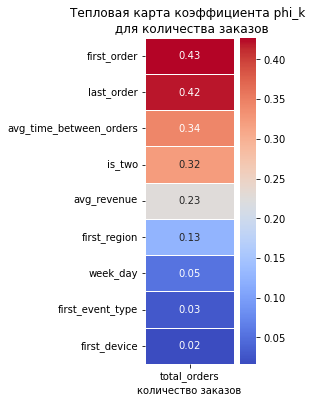

In [55]:
# Визуализируем полученные данные
# Строим тепловую карту
plt.figure(figsize = (2,6))

data_heatmap = (correlation_matrix.loc[correlation_matrix.index != 'total_orders']
                [['total_orders']].sort_values(by='total_orders', ascending=False)
               )
sns.heatmap(data_heatmap,
           annot=True,
           fmt='.2f',
           cmap='coolwarm',
           linewidth=0.5
           )
# Настраиваем подписи
plt.title('Тепловая карта коэффициента phi_k \n для количества заказов')
plt.xlabel('количество заказов')


# выводим тепловую карту
plt.show()

Из данных можем понять, что количество заказов не имеет явной высокой корреляции, а вот умеренная корреляция наблюдается у следующих столбцов:

- дата первого заказа (first_order) - **0.43**
- дата последнего заказа (last_order) - **0,42**
- в меньшей степени от времени между заказами - **0,34**

Минимальная корреляция со столбцами: 
- с типом первого мероприятия
- с типов устройства с которого был сделан заказ
- с первым регионом

Столбец "is_two" имеет корреляцию **0.32**, что вполне ожидаемо так как столбец создан из данных с заказами и он не являеься независимым фактором возврата

Поэтому допольнительное деление по сегментам количества заказов не требуется 

<function matplotlib.pyplot.show(close=None, block=None)>

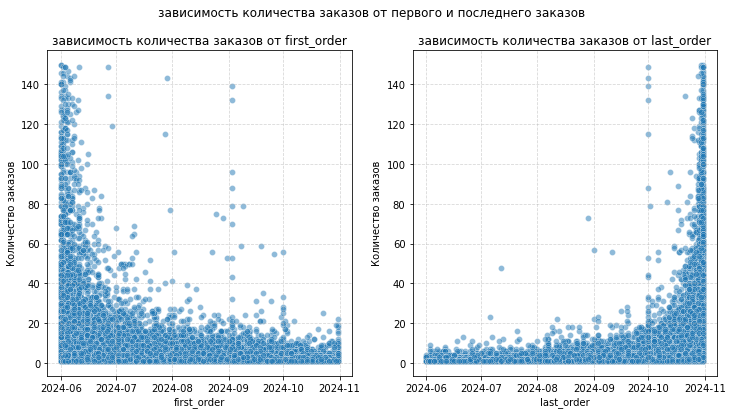

In [56]:
fig, axes = plt.subplots(1,2, figsize=(12, 6))

for ax, (name, values) in zip(axes, user_profile[['first_order', 'last_order']].items()):
    sns.scatterplot(
        data=user_profile,
        x=user_profile[name],
        y=user_profile['total_orders'],
        alpha=0.5,
        legend=True,
        ax=ax
        )
    ax.set_title(f'зависимость количества заказов от {name}')
    ax.set_xlabel(name)
    ax.set_ylabel('Количество заказов')
    ax.grid(True, alpha=0.5, linestyle='--')

plt.suptitle('зависимость количества заказов от первого и последнего заказов')
plt.show

По графикам и представленной выборке. Можно сказать, что в левой части графика `first_order`, в июне мы видим столб, к ноябрю количество заказов падает. Это может говорить о начале летне - осеннего сезона и люди массово бронируют билеты на мероприятия или была какя-то массовая акция.

с июля затишье - количество первых заказов небольшое, как и новых клиентов. Зеркальная ситуация на правом графике `last_order` с июня по октябрь количество заказов небольшое, но в течение сентября - октября начинается рост заказов, возможны крупные мероприятия под закрытие сезона, бронирование билетов на мероприятия нового года

Принмая во внимание ограниченность выборки. Таким образом можно составить гипотезу: 

Пики активности пользователей прослеживаются в июне и в октебре, с июля по октябрь более стабильное поведение пользователей, заказы и доходы получают в основном от постоянных клиентов, которые делают небольшие заказы. Это относится как к группе пользователей с возвратом, так и к единоразовым покупкам билетов

Для проверки гипотезы посчитаем распределение заказов по месяцам по исходным данными

In [57]:
monthly_orders = df.groupby(df['order_dt'].dt.month_name())['order_id'].count().sort_values(ascending = False)
print('Количество заказов по месяцам:')
display(monthly_orders)

Количество заказов по месяцам:


order_dt
October      99130
September    68953
August       43189
July         37927
June         32638
Name: order_id, dtype: int64

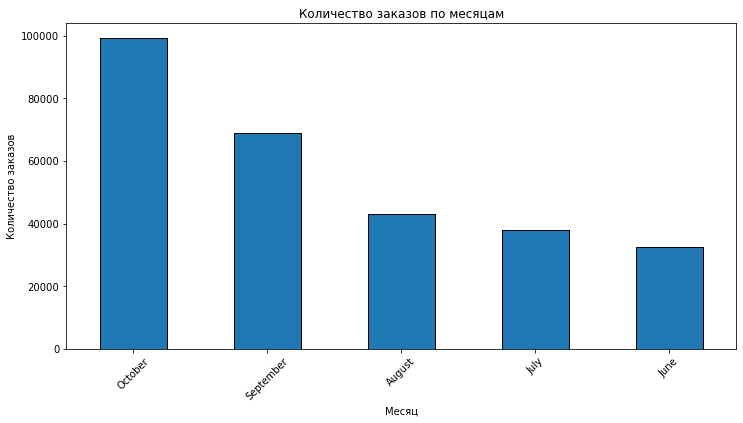

In [58]:
plt.figure(figsize=(12, 6))

monthly_orders.plot(kind='bar', 
                    edgecolor='black',
                    rot=45)
plt.title('Количество заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')

plt.show()

Судя по данным гипотеза сезонности не подтверждается, количество заказов в представленном периоде с июня по конец октября постоянно растет и имеет пик в октябре.

К тому же для точного определения сезонности, необходимо иметь данные за весь год.

А наблюдаемые пики на графиках зависимости количества заказов от даты первого и последнего заказов могут объясняться ограниченностью выборки. Пользователи, которые в сервисе были до июня 2024 года сделав заказ в июне автоматически попадают в группу новичков с первым заказом в июне.
А ноябрьсий пик возможен из-за окончания наблюдений (правый срез данных). Пользователь мог и не уходить из сервиса и заказы сделанные в октябре автоматически стали датой последнего заказа. 

[Назад к оглавлению](#Оглавление)

# 5. Общий вывод и рекомендации

## 1. Общий обзор проделанной работы

В данном проекте мы провели анализ пользователей яндекс афишы, с целью предоставить рекомендации маркетологам по удержанию клиетов, для этого было проведено:
 1. Изучили типы и содержимое данных, 
 2. Провели анализ и характер пропусков
 3. Провели поиск и удаление явных и неявных дубликатов. **44 (0.02%)** дубликата удалено
 4. Создали булевый столбец `revenue_rub`, , включающий данные в тенге с конвертацией в рубли
 5. Провели оптимизацию размерности числовых данных
 6. провели фильтрацию данных от выбросов по 99му процентилю и отрицательных, и нулевых значений в столбце revenue_rub общее количество удаленных строк после предобработки: **8774** в процентах: **3.02%** от общего числа строк исходного датафрейма 290611 строк.
 7. Создали профиль пользователя с агрегированными данными, количество строк **21704**
 8. провели фильтрацию по выбросам. Удалено строк **349 строк (1.61%)**
 9. Провели исследовательский анализ данных, в ходе которого были исследованы:
    - Изучили распределения пользователей по признакам
    - Проанализировали возврат пользователей
    - Проверили продуктовые гипотезы
    - Провели исследование поведения пользователей через показатели выручки и состава заказа
    - Исследовали временные характеристики первого заказа и их влияния на повторные покупки
    - Провели корреляционный анализ количества покупок и признаков пользователя

## 2. Результаты анализа

 - всего уникальных клиентов **21933**, причем один из клиентов сделал **10251** заказ
 - **2** типа устройств, с которых делались заказы. В лидерах мобильное устройство с **232457** заказами
 - **15248** проведенных уникальных мероприятий
 - представлено **7** типов мероприятий, в лидерах концерты - **115265**
 - **36** билетных агентов, лидер билеты без проблем - **63502** заказов
 - **81** регион, топ - каменевский регион - **91044** заказов
 - **352** города, топ - глиногорск - **89432** заказов, в столбце тип мероприятия есть категория другое. В этой категории указаны типы мероприятий не вошедшие в 6 представленных категорий.
 - столбец `revenue_rub` - Среднее **528.90** и медиана **358.35**, стандартное отклонение **511,70**, но все-равно еще большое и большой размах, говорят о выбросах в данных макс значение после фильтрации изменилось с **81174.5** до **2628,4**, что уже ближе к реальности. Из графика распределения видно, что имеется длинный правый хвост, 50% данных находятся в пределах от примерно **122.7** до **798.07** рублей.
 - столбец `days_since_prev` - среднее значение **3.25** медиана **0** макс значение **148** говорит, что есть выбросы,  Для **75% по 75 процентилю** повторных заказов временной интервал между заказами не превышает 1 дня (повторный заказ делается в течении суток). График экстремально смещен влево к нулевым значениям с большим правым хвостом. Соответственно гипотеза о том что повторные заказы совершаются в пределах 1 дня подтверждается.    
 - столбец `ticket_counts` - мин заказ **1** билет, макс **47**, большой размах, среднее **2,74** и медиана **3,00**. Из графиков видно, что самое большое количество билетов в одном заказе - **3**. Также в большинстве случаев в одном заказе от 2х до 6 билетов, но есть и единичные случаи превышающие эти значения, такие как оптовые закупки с 47 билетами
 
### Точки входа

 - **по первому типу события**. Очень сильно выделяются 2 типа: `концерты` - **9541 (44,7%)**, `театр` **4231 (19,8%). 3й тип `другое` с 5195 (24,33%)** не может сказать что-либо так как в эту категорию входит множество других типов мероприятий, которые не вошли в другие представленные категории, остальные категории варьируются от `елки` - **97(0.45%)** до `стендап` **1113 (5.21%)**
 - **по типу платформы с которого делался первый заказ**. В данных представлено 2 типа `мобильные устройства` и `ПК`. С явным преимуществом выделяются `мобильные устройства` с **17702 (82.9%)** против `ПК` с **3649 (17.1%)**
 - **по первому региону**. Очень сильно по отношению к остальным регионам выделяются 3: `Каменевский регион`, `североярская область` и `широковская область` с **6918 (32.4%)**, **3759 (17.6%)**, **1228 (5.75%)** соответственно. остальные регионы варьируются с **1 (0.005%)** пользователя до **676 (3.17%)** пользователей
 
Из этих данных вырисовываются "точки входа": 
 - Пользователи больше всего в первый раз заказывают билеты на `концерты`, что является вполне корректным, концертные события имеют высокую популярность, и в `театр` для культурного слоя пользователей. 
 - Первые заказы делались с `мобильных устройств`, что характерно для текущего времени, когда люди совершают быстрые покупки через приложения, иногда даже "на ходу". 
 - Первые регионы `Каменевский регион`, `североярская область` и `широковская область`. Это может быть связано с плотностью населения и активностью.
 
### Доли возвратов

 - По типу мероприятия - по 4м типам мероприятий из 7, доля сделавших 2 и более заказа примерно равна общей доле пользователей сделавших 2 и более заказа равной **61.07%** и варьируется от **60.74%** у `стендапа` до **63.90%** у `выставок`. Другие 3 ниже общей доли это `другое`, `елки`, `спорт` - **59.2%**, **56.7%**, **54.97%**. 2а лидера по количеству пользователей из предыдущей задачи концерты и театры имеют **61.56%** и **63.25%**

 - типу устройств - доля пользователей сделавших 2 и более заказа c `ПК` составляет **63.25%** и немного превосходит `мобильные устройства` - **60.62%**, что практически недалеко от общей доли. Таким образом тип устройства вряд ли влияет на возврат

 - `Регион` - в данных диапазон **26** регионов превышают общую долю в **61,07%**, лидер на графике со **100%** `вурхозерский край` далеко не показатель этот регион с наименьшим числом пользователей, а вот лидеры по количеству пользователей `Каменевский регион`, `североярская область` и `широковская область` имеют **61.63%**, **63.85%** и **64.33%**, что выше общей средней доли

По долям заметно выраженных причин возврата не выявлено все показания варьируются вокруг общей доли пользователя в **61.07%**

### Проверка продуктовых гипотез
 - **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
 - **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.
 

**Гипотеза 1 не подтвердилась**, наоборот возвратов больше у тех кто первый раз оформил заказ на концерты 
 

**Выводы по гипотезе 2:**

Доля возвратов с увеличением активности увеличивается не подтверждается, в этом случае линия приближенно была бы убывающей прямой слева направо. В нашем случае это не так.

**Гипотеза 2 опровергнута**

### Распределение по средней выручке

Условимся, что `первая группа` - меньше 2х заказов, `Вторая группа` - 2 заказа и более.

Диапазон у `первой группы` от **~0** до **~400.** с пиком в районе **~0**

Диапазон `второй группы` от **~300** до **~800** с пиком в районе **~500**

- пользователи с 1м заказом совершают более мелкие по цене покупки, чем `вторая группа`, также имеет длинный правый хвост с редкими дорогими заказами. Это сравнивает среднюю этой группы **552.79** со средним второй группы **551.54**. Медиана у первой группы **388.81** меньше чем у второй **503.16**, что подтверждает гипотезу.

У `второй группы` более стабильная и высокая медианная выручка, по сравнению с `первой группой`, приносящая больший вклад в общую сумму выручки.

Различия скорей носят структурированный характер, а не в средней или максимальной выручке, которая тоже идентична.

### Зависимость возврата от дня недели

По дням недели количество пользователей находится в диапазоне от **2739** в воскресенье до **3275** в субботу

Максимальные значения по возврату приходится на `субботу` и `понедельник`  **3275 (~62.6%)** и **2879 (62.4%)** соответственно.

Отсюда можно сделать вывод, что большее число пользователей покупают билеты на мероприятия в `субботу` и имеют более высокий возврат, потому что `суббота` это выходной и у работающих людей это более спокойный день недели для обдуманного планирования следующей недели. В `понедельник` тоже высокий возврат, но с меньшим количеством пользователей, так как это первый день недели на работе, неделя может быть еще не распланирована и пока еще есть время на планирование похода на мероприятие на конец недели.

Самые низкие возвраты в `четверг` **3086 (59.3%)** и `пятницу` **3210 (59.7%)**, это конец рабочей недели и в эти дни люди часто покупают билеты спонтанно и единоразово перед выходными. Поэтому большое количество пользователей и малый процент возврата. 

В `воскресенье` наблюдается самое минимальное количество пользователей, а возврат **59.95%** находиться на одном низком уровне с `четвергом` и `пятницей`. Последний день выходных чаще всего занимает подготовка к рабочей неделе или решение домашних проблем

**Вывод:** Метрики возврата различаются в зависимости от дня недели

### Зависимость количества заказов от дат первого и последнего заказа

По графикам и представленной выборке. Можно сказать, что в левой части графика `first_order`, в июне мы видим столб, к ноябрю количество заказов падает. Это может говорить о начале летне - осеннего сезона и люди массово бронируют билеты на мероприятия или была какя-то массовая акция.

с июля затишье - количество первых заказов небольшое, как и новых клиентов. Зеркальная ситуация на правом графике `last_order` с июня по октябрь количество заказов небольшое, но в течение сентября - октября начинается рост заказов, возможны крупные мероприятия под закрытие сезона, бронирование билетов на мероприятия нового года

Принмая во внимание ограниченность выборки. Таким образом можно составить гипотезу: 

Пики активности пользователей прослеживаются в июне и в октебре, с июля по октябрь более стабильное поведение пользователей, заказы и доходы получают в основном от постоянных клиентов, которые делают небольшие заказы. Это относится как к группе пользователей с возвратом, так и к единоразовым покупкам билетов

Для проверки гипотезы посчитаем распределение заказов по месяцам по исходным данными 

Дополнительная проверка гипотезу не подтвердила

А наблюдаемые пики на графиках зависимости количества заказов от даты первого и последнего заказов могут объясняться ограниченностью выборки. Пользователи, которые в сервисе были до июня 2024 года сделав заказ в июне автоматически попадают в группу новичков с первым заказом в июне.
А ноябрьсий пик возможен из-за окончания наблюдений (правый срез данных). Пользователь мог и не уходить из сервиса и заказы сделанные в октябре автоматически стали датой последнего заказа.
 
 

## Общие выводы

- **Портрет и поведение пользователя:**
   
   Подавляющее большиство первых заказов **(~82,9%)** совершаются с **мобильных устройств**. Это делает мобильное приложение или адаптивную веб версию ключевым "траффиком". **(~75% по 75му процентилю)** повторных покупок совершается в течении одного дня. Обычный размер заказа составляет **2-3 билета**.
 
 
 - **Точки входа и лидеры категорий:**
   
   Главным типом мероприятия для привлечения клиентов выступают **концерты (~44.7% первых заказов)** и **театры (19.8%)**. Лидером среди регионов является **Каменевский регион**, среди городов - **Глиногорск**
 
 
 - **Удержание и выручка**:
   
   Общая доля пользователей, совершивших 2 и более заказа, составляет около **61.07%**. Лояльные клиенты генерируют более стабильную и высокую медианную выручку (медиана **503.16 руб**. против **388.81 руб.** у новичков)
 
 
 - **Влияние дней недели:**
   
   Наибольшая вероятность возврата за повторной покупкой приходится на **субботу и понедельник (около 62.5%)**. 
 
 
 - **Опровержение гипотез:**
   
   Продуктовые гипотезы **не подтвердились**. Возвратов больше у тех кто первый раз оформил заказ на концерты. Доля возвратов с увеличением активности увеличивается - не подтверждается

## Рекомендации

- Поскольку  подавляющее большиство заказов **(~82,9%)** совершаются с **мобильных устройств**. Можно направить усилия на модернизацию или увеличение функционала и удобство мобильного приложения или адаптивного под мобильные устройства веб-сервиса


- Так как большинство покупок совершается в течение одного дня можно наладить push рассылки сразу или через несколько часов после сделанного заказа


- Сделать упор в рекламных кампаниях на концерты и спектакли в театрах


- Увеличить интенсивность рекламных рассылок в пятницу вечером, субботу и понедельник, это дни когда люди склонны возвращаться.